
# Trading atlas pairs through changing beta regimes

The atlas relationships need not cease being pairs when their hedge ratios move. The relevant question is whether the strategy distinguishes:

- a **temporary pricing innovation**, which may be faded; and
- a **persistent beta change**, which should be incorporated into the hedge rather than treated as ever-increasing moneyness.

The current implementation re-estimates a Kalman beta at every decision, but then applies that latest beta retrospectively to the entire spread window. This notebook compares that construction with genuinely time-varying, causal alternatives:

1. the exact current atlas calculation;
2. rolling OLS beta using 60, 120, and 250 prior closes;
3. a random-walk Kalman alpha/beta model with one pooled parameter set;
4. the same model with `Q` and `R` calibrated separately for every pair using only days 1–250.
5. a better-identified version with a static intercept and only beta allowed to random-walk, again compared in pooled and pair-specific forms.

For the dynamic Kalman models, the runtime score is the standardized **one-step innovation**

\[
z_t = \frac{y_t - H_t\hat\theta_{t|t-1}}
{\sqrt{H_tP_{t|t-1}H_t^\top + R}},
\]

not a historical spread recomputed using today's beta. Parameter calibration uses the first 250 closes; tracking and trading are evaluated on days 251–750. Threshold selection is performed on days 251–500 and reported separately on days 501–750.

This remains research on a preselected atlas and therefore is not unbiased proof of future profitability.


In [1]:

from pathlib import Path
import types
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from IPython.display import display, Markdown

warnings.filterwarnings("ignore")
plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 240)

ROOT = Path.cwd()
OUT_DIR = ROOT / "cointegration_output" / "dynamic_beta_atlas"
OUT_DIR.mkdir(parents=True, exist_ok=True)

prices_df = pd.read_csv(ROOT / "prices.txt", sep=r"\s+")
names = prices_df.columns.to_list()
prices = prices_df.to_numpy(float).T
LP = np.log(prices)
n_inst, n_days = prices.shape

strategy_path = ROOT / "teamName.py"
strategy = types.ModuleType("teamName_source")
strategy.__file__ = str(strategy_path)
exec(compile(strategy_path.read_text(encoding="utf-8"), str(strategy_path), "exec"), strategy.__dict__)
atlas_pairs = list(strategy.ATLAS_PAIRS)

CALIBRATION_END = 250
EVAL_START = 249       # decision close; PnL starts at the next close
EVAL_END = 748
LEG = float(strategy.LEG)

print(f"{n_inst} assets, {n_days} closes, {len(atlas_pairs)} atlas pairs")
print("Calibration: observations 1–250; evaluation PnL: days 251–750")


51 assets, 750 closes, 13 atlas pairs
Calibration: observations 1–250; evaluation PnL: days 251–750



## Dynamic relationship estimators

The custom Kalman model centres the explanatory log price around its first-60-day mean. This is only a numerical reparameterization: beta is unchanged, but the intercept and beta process noises become less collinear.

For each pair, maximum likelihood estimates three positive variances on observations 61–250:

- `q_alpha`: random-walk intercept process variance;
- `q_beta`: random-walk beta process variance;
- `R`: observation/temporary-spread variance.

No forward trading PnL is used in this calibration. A pooled model uses the median calibrated variances across all 13 pairs, giving a direct test of whether universal dynamics are adequate.

Because a freely moving intercept and beta can explain the same level change, the notebook also fits a constrained **static-intercept / dynamic-beta** model. This is the cleaner test of the claim that the relationships persist while beta changes.


In [2]:

def initial_regression(y, x, init=60):
    x_ref = float(x[:init].mean())
    X = np.column_stack([np.ones(init), x[:init] - x_ref])
    theta = np.linalg.lstsq(X, y[:init], rcond=None)[0]
    residual = y[:init] - X @ theta
    R0 = max(float(np.var(residual)), 1e-8)
    P0 = R0 * np.linalg.pinv(X.T @ X)
    P0 += np.eye(2) * 1e-8
    return x_ref, theta, P0, R0


def run_random_walk_kf(y, x, q_alpha, q_beta, R, init=60):
    '''Causal random-walk alpha/beta filter; arrays contain one-step priors.'''
    x_ref, theta, P, _ = initial_regression(y, x, init)
    n = len(y)
    alpha = np.full(n, np.nan)
    beta = np.full(n, np.nan)
    innovation = np.full(n, np.nan)
    innovation_var = np.full(n, np.nan)
    z = np.full(n, np.nan)
    filtered_beta = np.full(n, np.nan)
    Q = np.diag([q_alpha, q_beta])
    I = np.eye(2)

    for t in range(init, n):
        P_prior = P + Q
        H = np.array([1.0, x[t] - x_ref])
        pred = float(H @ theta)
        v = float(y[t] - pred)
        S = max(float(H @ P_prior @ H + R), 1e-12)

        alpha[t] = float(theta[0] - theta[1] * x_ref)
        beta[t] = float(theta[1])
        innovation[t] = v
        innovation_var[t] = S
        z[t] = v / np.sqrt(S)

        K = P_prior @ H / S
        theta = theta + K * v
        # Joseph form is stable and keeps P positive semidefinite.
        KH = np.outer(K, H)
        P = (I - KH) @ P_prior @ (I - KH).T + np.outer(K, K) * R
        P = 0.5 * (P + P.T)
        filtered_beta[t] = float(theta[1])

    return {
        "alpha": alpha, "beta": beta, "innovation": innovation,
        "innovation_var": innovation_var, "z": z,
        "filtered_beta": filtered_beta,
    }


def kalman_nll(log_variances, y, x, fit_end=CALIBRATION_END):
    q_alpha, q_beta, R = np.exp(log_variances)
    result = run_random_walk_kf(y[:fit_end], x[:fit_end], q_alpha, q_beta, R)
    valid = np.arange(60, fit_end)
    v = result["innovation"][valid]
    S = result["innovation_var"][valid]
    if not np.all(np.isfinite(v)) or not np.all(np.isfinite(S)):
        return 1e100
    return float(0.5 * np.sum(np.log(S) + v * v / S))


def calibrate_pair(y, x):
    _, _, _, R0 = initial_regression(y[:CALIBRATION_END], x[:CALIBRATION_END])
    initial = np.log([max(R0 * 1e-3, 1e-10), max(R0 * 1e-4, 1e-11), R0])
    bounds = [(-25.0, -3.0), (-25.0, -3.0), (-18.0, -1.0)]
    fit = minimize(
        kalman_nll, initial, args=(y, x), method="L-BFGS-B", bounds=bounds,
        options={"maxiter": 250, "ftol": 1e-10},
    )
    q_alpha, q_beta, R = np.exp(fit.x)
    return q_alpha, q_beta, R, bool(fit.success), float(fit.fun)


def beta_only_nll(log_variances, y, x, fit_end=CALIBRATION_END):
    q_beta, R = np.exp(log_variances)
    result = run_random_walk_kf(y[:fit_end], x[:fit_end], 1e-12, q_beta, R)
    valid = np.arange(60, fit_end)
    v = result["innovation"][valid]
    S = result["innovation_var"][valid]
    if not np.all(np.isfinite(v)) or not np.all(np.isfinite(S)):
        return 1e100
    return float(0.5 * np.sum(np.log(S) + v * v / S))


def calibrate_beta_only(y, x):
    '''Static intercept, pair-specific random-walk beta and observation noise.'''
    _, _, _, R0 = initial_regression(y[:CALIBRATION_END], x[:CALIBRATION_END])
    initial = np.log([max(R0 * 1e-4, 1e-11), R0])
    fit = minimize(
        beta_only_nll, initial, args=(y, x), method="L-BFGS-B",
        bounds=[(-25.0, -3.0), (-18.0, -1.0)],
        options={"maxiter": 250, "ftol": 1e-10},
    )
    q_beta, R = np.exp(fit.x)
    return q_beta, R, bool(fit.success), float(fit.fun)


def rolling_ols(y, x, window):
    n = len(y)
    alpha = np.full(n, np.nan)
    beta = np.full(n, np.nan)
    innovation = np.full(n, np.nan)
    innovation_var = np.full(n, np.nan)
    z = np.full(n, np.nan)
    for t in range(window, n):
        yy, xx = y[t-window:t], x[t-window:t]
        xc, yc = xx - xx.mean(), yy - yy.mean()
        b = float(xc @ yc / max(xc @ xc, 1e-18))
        a = float(yy.mean() - b * xx.mean())
        residual = yy - a - b * xx
        scale2 = max(float(np.var(residual)), 1e-12)
        v = float(y[t] - a - b * x[t])
        alpha[t], beta[t] = a, b
        innovation[t], innovation_var[t], z[t] = v, scale2, v / np.sqrt(scale2)
    return {
        "alpha": alpha, "beta": beta, "innovation": innovation,
        "innovation_var": innovation_var, "z": z,
        "filtered_beta": beta.copy(),
    }


def run_current_filter(y, x):
    '''One-pass reconstruction of teamName's universal-Q Kalman prior.'''
    theta = np.array([y[:60].mean() - x[:60].mean(), 1.0])
    P = np.eye(2) * 1e-2
    Q = np.eye(2) * 1e-5
    R = float(np.var(np.diff(y[:120] - x[:120])) + 1e-8)
    n = len(y)
    alpha = np.full(n, np.nan)
    beta = np.full(n, np.nan)
    innovation = np.full(n, np.nan)
    innovation_var = np.full(n, np.nan)
    z_innovation = np.full(n, np.nan)
    z_atlas = np.full(n, np.nan)
    active = np.zeros(n, dtype=bool)
    adf_t = np.full(n, np.nan)
    kappa = np.full(n, np.nan)

    for t in range(n):
        P_prior = P + Q
        H = np.array([1.0, x[t]])
        v = float(y[t] - H @ theta)
        S = max(float(H @ P_prior @ H + R), 1e-12)
        alpha[t], beta[t] = theta
        innovation[t], innovation_var[t] = v, S
        z_innovation[t] = v / np.sqrt(S)

        if t >= 129:
            spread = y[:t+1] - beta[t] * x[:t+1]
            recent = spread[-145:]
            z_atlas[t] = float(
                (recent[-1] - recent[:-1].mean()) / (recent[:-1].std() + 1e-12)
            )
            adf_t[t] = float(strategy._adf1_tstats(spread.reshape(-1, 1))[0])
            kappa[t] = float(strategy._ou_kappa(spread[-120:]))
            active[t] = bool(
                adf_t[t] < -2.9 and kappa[t] > 0.0
                and 0.27 <= abs(z_atlas[t]) <= 4.0
            )

        K = P_prior @ H / S
        theta = theta + K * v
        P = P_prior - np.outer(K, H) @ P_prior
        P = 0.5 * (P + P.T)

    return {
        "alpha": alpha, "beta": beta, "innovation": innovation,
        "innovation_var": innovation_var, "z": z_atlas,
        "innovation_z": z_innovation, "active": active,
        "adf_t": adf_t, "kappa": kappa,
        "filtered_beta": beta.copy(), "R": R,
    }


In [3]:

parameter_rows = []
pair_data = {}

for number, (i, j) in enumerate(atlas_pairs, start=1):
    label = f"{names[i]}~{names[j]}"
    y, x = LP[i], LP[j]
    q_alpha, q_beta, R, success, train_nll = calibrate_pair(y, x)
    beta_only_q, beta_only_R, beta_only_success, beta_only_nll_value = calibrate_beta_only(y, x)
    pair_data[label] = {
        "i": i, "j": j, "y": y, "x": x,
        "pair_kf": run_random_walk_kf(y, x, q_alpha, q_beta, R),
        "pair_beta_kf": run_random_walk_kf(y, x, 1e-12, beta_only_q, beta_only_R),
        "current": run_current_filter(y, x),
        "rolling_60": rolling_ols(y, x, 60),
        "rolling_120": rolling_ols(y, x, 120),
        "rolling_250": rolling_ols(y, x, 250),
    }
    parameter_rows.append({
        "pair": label, "q_alpha": q_alpha, "q_beta": q_beta, "R": R,
        "q_beta_over_R": q_beta / R, "q_alpha_over_R": q_alpha / R,
        "optimizer_success": success, "calibration_nll": train_nll,
        "beta_only_q_beta": beta_only_q, "beta_only_R": beta_only_R,
        "beta_only_q_over_R": beta_only_q / beta_only_R,
        "beta_only_optimizer_success": beta_only_success,
        "beta_only_calibration_nll": beta_only_nll_value,
        "current_universal_q": 1e-5,
        "current_pair_R": pair_data[label]["current"]["R"],
    })
    print(f"Calibrated {number:2d}/13 {label}: qβ={q_beta:.2e}, R={R:.2e}")

parameters = pd.DataFrame(parameter_rows)
pooled = {
    "q_alpha": float(np.median(parameters.q_alpha)),
    "q_beta": float(np.median(parameters.q_beta)),
    "R": float(np.median(parameters.R)),
}
pooled_beta_only = {
    "q_beta": float(np.median(parameters.beta_only_q_beta)),
    "R": float(np.median(parameters.beta_only_R)),
}

for label, data in pair_data.items():
    data["pooled_kf"] = run_random_walk_kf(
        data["y"], data["x"], pooled["q_alpha"], pooled["q_beta"], pooled["R"]
    )
    data["pooled_beta_kf"] = run_random_walk_kf(
        data["y"], data["x"], 1e-12,
        pooled_beta_only["q_beta"], pooled_beta_only["R"]
    )

parameters.to_csv(OUT_DIR / "pair_specific_kalman_parameters.csv", index=False)
print("\nPooled median parameters:", pooled)
print("Pooled static-intercept beta parameters:", pooled_beta_only)
display(parameters.round(10))


Calibrated  1/13 SMAH~ILVX: qβ=1.39e-07, R=2.66e-05


Calibrated  2/13 AENO~NWIG: qβ=1.34e-03, R=3.24e-05


Calibrated  3/13 EORC~NGTE: qβ=6.09e-08, R=1.89e-05


Calibrated  4/13 HUXZ~ACAC: qβ=1.27e-07, R=7.99e-06


Calibrated  5/13 CTGI~EELT: qβ=1.44e-08, R=1.52e-08


...

Calibrated 11/13 MTNS~ALUT: qβ=3.97e-04, R=6.12e-06


Calibrated 12/13 NAYO~SRTX: qβ=5.53e-07, R=1.52e-08


Calibrated 13/13 ALUT~CCNS: qβ=4.02e-11, R=1.52e-08



Pooled median parameters: {'q_alpha': 0.00039527219322053767, 'q_beta': 1.3856411835417878e-07, 'R': 6.118910080123803e-06}
Pooled static-intercept beta parameters: {'q_beta': 0.01693096800142903, 'R': 0.0009251661584628174}


,pair,q_alpha,q_beta,R,q_beta_over_R,q_alpha_over_R,optimizer_success,calibration_nll,beta_only_q_beta,beta_only_R,beta_only_q_over_R,beta_only_optimizer_success,beta_only_calibration_nll,current_universal_q,current_pair_R
0,SMAH~ILVX,0.000395,1.386000e-07,2.657260e-05,5.214540e-03,14.875154,True,-635.427805,5.773111e-03,0.000540,10.696513,True,-577.052863,0.00001,0.000383
1,AENO~NWIG,0.000269,1.335246e-03,3.236230e-05,4.125933e+01,8.321836,True,-655.707349,1.007000e-07,0.001165,0.000086,True,-544.767534,0.00001,0.000671
2,EORC~NGTE,0.000412,6.090000e-08,1.885540e-05,3.231267e-03,21.875500,True,-635.790156,8.014341e-03,0.000650,12.336727,True,-537.777952,0.00001,0.000667
3,HUXZ~ACAC,0.000404,1.268000e-07,7.990600e-06,1.587297e-02,50.503204,True,-642.130641,1.693097e-02,0.000907,18.666049,True,-524.936457,0.00001,0.000761
4,CTGI~EELT,0.000934,1.440000e-08,1.520000e-08,9.457566e-01,61316.154572,True,-566.999644,3.574370e-02,0.002305,15.506248,True,-438.134736,0.00001,0.001567
5,MHRM~EAFC,0.000411,0.000000e+00,4.895540e-05,7.692000e-07,8.387777,True,-625.173162,6.001795e-03,0.000925,6.487262,True,-544.914961,0.00001,0.000747
6,HETT~ULXY,0.000267,8.522455e-04,1.520000e-08,5.595841e+04,17530.964712,True,-675.754100,3.809077e-02,0.002435,15.644285,True,-440.309147,0.00001,0.001120
7,ACIX~ITPA,0.000166,9.424685e-04,1.520000e-08,6.188246e+04,10879.423939,True,-710.562243,6.511050e-03,0.000027,241.080840,True,-687.242394,0.00001,0.000285
8,FWWG~BLBT,0.000167,1.631155e-03,6.370900e-06,2.560321e+02,26.209148,True,-714.735750,2.563528e-02,0.000030,852.142964,True,-699.392266,0.00001,0.000245
9,RTTH~NAYO,0.001095,4.000000e-10,1.520000e-08,2.607164e-02,71930.062938,True,-552.242572,4.978707e-02,0.008817,5.646425,True,-300.534248,0.00001,0.001189



## Does pair-specific calibration improve later relationship tracking?

Tracking metrics use only observations 251–750. Lower RMSE and predictive negative log-likelihood are better. Innovation lag-1 correlation near zero means the model has absorbed persistent beta movement rather than leaving predictable same-direction errors.

Beta total variation is not a quality metric by itself; it shows how aggressively each estimator changes the hedge.


In [4]:

def lag1_corr(values):
    values = np.asarray(values, float)
    valid = np.isfinite(values)
    values = values[valid]
    return float(np.corrcoef(values[:-1], values[1:])[0, 1]) if len(values) > 2 else np.nan


tracking_rows = []
tracking_methods = [
    "current", "rolling_60", "rolling_120", "rolling_250",
    "pooled_kf", "pair_kf", "pooled_beta_kf", "pair_beta_kf",
]
eval_slice = slice(CALIBRATION_END, n_days)

for label, data in pair_data.items():
    for method in tracking_methods:
        result = data[method]
        v = result["innovation"][eval_slice]
        S = result["innovation_var"][eval_slice]
        b = result["beta"][eval_slice]
        valid = np.isfinite(v) & np.isfinite(S) & (S > 0)
        vv, SS = v[valid], S[valid]
        tracking_rows.append({
            "pair": label,
            "method": method,
            "observations": int(valid.sum()),
            "innovation_RMSE": float(np.sqrt(np.mean(vv * vv))),
            "innovation_MAE": float(np.mean(np.abs(vv))),
            "predictive_NLL_per_obs": float(np.mean(0.5 * (np.log(SS) + vv * vv / SS))),
            "innovation_lag1_corr": lag1_corr(vv),
            "beta_daily_abs_change": float(np.nanmedian(np.abs(np.diff(b)))),
            "beta_total_variation": float(np.nansum(np.abs(np.diff(b)))),
        })

tracking = pd.DataFrame(tracking_rows)
tracking.to_csv(OUT_DIR / "dynamic_beta_tracking_metrics.csv", index=False)

tracking_aggregate = (
    tracking.groupby("method", as_index=False)
    .agg(
        median_RMSE=("innovation_RMSE", "median"),
        median_MAE=("innovation_MAE", "median"),
        median_NLL=("predictive_NLL_per_obs", "median"),
        median_abs_lag1_corr=("innovation_lag1_corr", lambda x: np.median(np.abs(x))),
        median_beta_daily_change=("beta_daily_abs_change", "median"),
    )
    .sort_values("median_NLL")
)
display(tracking_aggregate.round(6))

comparison = tracking.pivot(index="pair", columns="method", values="predictive_NLL_per_obs")
pair_specific_nll_wins = int((comparison.pair_kf < comparison.pooled_kf).sum())
rmse_comparison = tracking.pivot(index="pair", columns="method", values="innovation_RMSE")
pair_specific_rmse_wins = int((rmse_comparison.pair_kf < rmse_comparison.pooled_kf).sum())
print(f"Pair-specific KF beats pooled KF on OOS NLL for {pair_specific_nll_wins}/13 pairs")
print(f"Pair-specific KF beats pooled KF on OOS RMSE for {pair_specific_rmse_wins}/13 pairs")
beta_comparison = tracking.pivot(index="pair", columns="method", values="predictive_NLL_per_obs")
beta_rmse_comparison = tracking.pivot(index="pair", columns="method", values="innovation_RMSE")
beta_nll_wins = int((beta_comparison.pair_beta_kf < beta_comparison.pooled_beta_kf).sum())
beta_rmse_wins = int((beta_rmse_comparison.pair_beta_kf < beta_rmse_comparison.pooled_beta_kf).sum())
print(f"Pair-specific beta-only KF beats pooled beta-only KF on OOS NLL for {beta_nll_wins}/13 pairs")
print(f"Pair-specific beta-only KF beats pooled beta-only KF on OOS RMSE for {beta_rmse_wins}/13 pairs")


,method,median_RMSE,median_MAE,median_NLL,median_abs_lag1_corr,median_beta_daily_change
4,pooled_kf,0.020697,0.016544,-3.377130,0.037419,0.000585
2,pair_kf,0.020670,0.016537,-3.376936,0.036472,0.001076
0,current,0.029024,0.023054,-3.027092,0.573457,0.001599
1,pair_beta_kf,0.027375,0.021194,-2.608822,0.323437,0.031981
3,pooled_beta_kf,0.026053,0.020650,-2.584354,0.313517,0.032054
7,rolling_60,0.045812,0.037653,-2.474925,0.891240,0.016301
6,rolling_250,0.053833,0.042742,-2.391963,0.901447,0.002441
5,rolling_120,0.053608,0.043004,-2.391089,0.914594,0.006259


Pair-specific KF beats pooled KF on OOS NLL for 8/13 pairs
Pair-specific KF beats pooled KF on OOS RMSE for 8/13 pairs
Pair-specific beta-only KF beats pooled beta-only KF on OOS NLL for 8/13 pairs
Pair-specific beta-only KF beats pooled beta-only KF on OOS RMSE for 6/13 pairs



## Trading comparison

Every candidate position is formed at one close and marked at the next. Turnover costs are 1 bp. Two sizing policies are compared:

- `equal`: the current atlas uses equal ±$10,000 legs;
- `dynamic_beta`: dollar exposure in the second asset is `-beta` times exposure in the first, with both legs kept inside the $10,000 instrument limit.

The dynamic estimators trade their causal one-step innovation z-score. The exact current atlas retains its ADF, kappa, 145-day z and dead-zone gates. Results sum standalone pair PnLs before shared-leg portfolio netting, so they compare signal constructions rather than reproduce total `teamName.py` PnL.


In [5]:

def score_fn(pnl):
    pnl = np.asarray(pnl, float)
    mu, sigma = float(pnl.mean()), float(pnl.std())
    if mu <= 0 or sigma < 1e-10:
        return mu
    sharpe = np.sqrt(250.0) * mu / sigma
    return float(mu * sharpe * sharpe / (sharpe * sharpe + 1.0))


def pnl_metrics(pnl):
    pnl = np.asarray(pnl, float)
    sigma = float(pnl.std())
    cumulative = np.r_[0.0, np.cumsum(pnl)]
    return {
        "net_pnl": float(pnl.sum()),
        "mean_pnl": float(pnl.mean()),
        "annual_sharpe": float(np.sqrt(250.0) * pnl.mean() / sigma) if sigma > 0 else np.nan,
        "score": score_fn(pnl),
        "hit_rate": float(np.mean(pnl > 0)),
        "max_drawdown": float(np.min(cumulative - np.maximum.accumulate(cumulative))),
    }


def backtest_pair(data, method, threshold, sizing):
    i, j = data["i"], data["j"]
    result = data[method]
    previous = np.zeros(2, dtype=int)
    pnl = []
    turnover = 0.0
    active_days = 0
    for day in range(EVAL_START, EVAL_END + 1):
        beta = float(result["beta"][day])
        if method == "current":
            active = bool(result["active"][day])
            z = float(result["z"][day])
        else:
            z = float(result["z"][day])
            active = bool(np.isfinite(z) and threshold <= abs(z) <= 4.0 and np.isfinite(beta) and beta > 0)
        target = np.zeros(2, dtype=int)
        if active:
            direction = -np.sign(z)
            if sizing == "dynamic_beta":
                leg_i = LEG / max(1.0, abs(beta))
                dollars_i = direction * leg_i
                dollars_j = -direction * beta * leg_i
            else:
                dollars_i = direction * LEG
                dollars_j = -direction * LEG
            target[0] = int(dollars_i / prices[i, day])
            target[1] = int(dollars_j / prices[j, day])
            active_days += 1
        delta = target - previous
        day_turnover = float(prices[i, day] * abs(delta[0]) + prices[j, day] * abs(delta[1]))
        day_pnl = float(
            target[0] * (prices[i, day + 1] - prices[i, day])
            + target[1] * (prices[j, day + 1] - prices[j, day])
            - 0.0001 * day_turnover
        )
        pnl.append(day_pnl)
        turnover += day_turnover
        previous = target
    return np.asarray(pnl), turnover, active_days


thresholds = [0.27, 0.5, 1.0, 1.5, 2.0]
trade_methods = [
    "rolling_60", "rolling_120", "rolling_250", "pooled_kf", "pair_kf",
    "pooled_beta_kf", "pair_beta_kf",
]
sizings = ["equal", "dynamic_beta"]
portfolio_pnl = {}
trade_rows = []

for method in trade_methods:
    for sizing in sizings:
        for threshold in thresholds:
            total = np.zeros(EVAL_END - EVAL_START + 1)
            total_turnover = 0.0
            total_active = 0
            for label, data in pair_data.items():
                pair_pnl, turnover, active_days = backtest_pair(data, method, threshold, sizing)
                total += pair_pnl
                total_turnover += turnover
                total_active += active_days
            key = (method, sizing, threshold)
            portfolio_pnl[key] = total
            for period, values in {
                "development_251_500": total[:250],
                "later_501_750": total[250:],
                "all_251_750": total,
            }.items():
                trade_rows.append({
                    "method": method, "sizing": sizing, "threshold": threshold,
                    "period": period, "turnover": total_turnover,
                    "pair_active_days": total_active, **pnl_metrics(values),
                })

# Exact current atlas signals under equal and dynamic-beta sizing.
for sizing in sizings:
    total = np.zeros(EVAL_END - EVAL_START + 1)
    total_turnover = 0.0
    total_active = 0
    for label, data in pair_data.items():
        pair_pnl, turnover, active_days = backtest_pair(data, "current", np.nan, sizing)
        total += pair_pnl
        total_turnover += turnover
        total_active += active_days
    portfolio_pnl[("current", sizing, np.nan)] = total
    for period, values in {
        "development_251_500": total[:250],
        "later_501_750": total[250:],
        "all_251_750": total,
    }.items():
        trade_rows.append({
            "method": "current", "sizing": sizing, "threshold": np.nan,
            "period": period, "turnover": total_turnover,
            "pair_active_days": total_active, **pnl_metrics(values),
        })

trades = pd.DataFrame(trade_rows)
trades.to_csv(OUT_DIR / "dynamic_beta_trading_sweep.csv", index=False)

# Select one common threshold per method/sizing on development score only.
selection_rows = []
for method in trade_methods:
    for sizing in sizings:
        dev = trades[
            (trades.method == method) & (trades.sizing == sizing)
            & (trades.period == "development_251_500")
        ].sort_values("score", ascending=False)
        chosen = float(dev.iloc[0].threshold)
        for period in ["development_251_500", "later_501_750", "all_251_750"]:
            row = trades[
                (trades.method == method) & (trades.sizing == sizing)
                & (trades.threshold == chosen) & (trades.period == period)
            ].iloc[0]
            selection_rows.append({
                "method": method, "sizing": sizing,
                "development_selected_threshold": chosen,
                "period": period, "net_pnl": row.net_pnl,
                "mean_pnl": row.mean_pnl, "annual_sharpe": row.annual_sharpe,
                "score": row.score, "max_drawdown": row.max_drawdown,
            })

for sizing in sizings:
    for period in ["development_251_500", "later_501_750", "all_251_750"]:
        row = trades[
            (trades.method == "current") & (trades.sizing == sizing)
            & (trades.period == period)
        ].iloc[0]
        selection_rows.append({
            "method": "current", "sizing": sizing,
            "development_selected_threshold": np.nan,
            "period": period, "net_pnl": row.net_pnl,
            "mean_pnl": row.mean_pnl, "annual_sharpe": row.annual_sharpe,
            "score": row.score, "max_drawdown": row.max_drawdown,
        })

selected = pd.DataFrame(selection_rows)
selected.to_csv(OUT_DIR / "development_selected_trading_results.csv", index=False)
display(selected[selected.period == "later_501_750"].sort_values("score", ascending=False).round(3))

# Pair-level attribution for the viable multiple-beta candidate.
rolling250_threshold = float(
    selected[
        (selected.method == "rolling_250") & (selected.sizing == "equal")
        & (selected.period == "development_251_500")
    ].development_selected_threshold.iloc[0]
)
pair_comparison_rows = []
for label, data in pair_data.items():
    candidates = {
        "current_equal": backtest_pair(data, "current", np.nan, "equal")[0],
        "rolling250_equal": backtest_pair(data, "rolling_250", rolling250_threshold, "equal")[0],
        "rolling250_dynamic_beta": backtest_pair(data, "rolling_250", rolling250_threshold, "dynamic_beta")[0],
    }
    for candidate, values in candidates.items():
        for period, period_values in {
            "development_251_500": values[:250],
            "later_501_750": values[250:],
            "all_251_750": values,
        }.items():
            pair_comparison_rows.append({
                "pair": label, "candidate": candidate, "period": period,
                **pnl_metrics(period_values),
            })
pair_comparison = pd.DataFrame(pair_comparison_rows)
pair_comparison.to_csv(OUT_DIR / "rolling250_pair_attribution.csv", index=False)
display(
    pair_comparison[pair_comparison.period == "later_501_750"]
    .pivot(index="pair", columns="candidate", values="net_pnl")
    .round(2)
)


,method,sizing,development_selected_threshold,period,net_pnl,mean_pnl,annual_sharpe,score,max_drawdown
13,rolling_250,equal,0.50,later_501_750,94353.443,377.414,7.619,371.023,-2495.264
16,rolling_250,dynamic_beta,0.50,later_501_750,92532.652,370.131,8.227,364.742,-2124.344
43,current,equal,NaN,later_501_750,91813.471,367.254,7.375,360.623,-3833.225
46,current,dynamic_beta,NaN,later_501_750,84634.473,338.538,7.384,332.440,-3364.546
7,rolling_120,equal,0.27,later_501_750,82822.298,331.289,6.340,323.248,-3028.415
10,rolling_120,dynamic_beta,0.27,later_501_750,73151.906,292.608,6.059,284.848,-2692.374
1,rolling_60,equal,0.27,later_501_750,70000.704,280.003,5.665,271.541,-4921.446
4,rolling_60,dynamic_beta,0.27,later_501_750,49876.114,199.504,4.562,190.358,-3592.452
37,pair_beta_kf,equal,0.50,later_501_750,36883.898,147.536,5.064,141.999,-2156.913
40,pair_beta_kf,dynamic_beta,0.50,later_501_750,33264.719,133.059,4.905,127.750,-2431.310


candidate,current_equal,rolling250_dynamic_beta,rolling250_equal
pair,,,
ACIX~ITPA,3836.13,3656.47,3406.79
AENO~NWIG,8538.18,7670.51,7705.15
ALUT~CCNS,6501.85,7240.64,7811.73
CTGI~EELT,14911.98,12944.85,14114.08
EORC~NGTE,16080.00,11687.53,13119.80
FWWG~BLBT,5190.65,5245.28,5395.36
HETT~ULXY,7037.88,8213.86,8176.38
HUXZ~ACAC,9875.25,7923.91,7946.62
MHRM~EAFC,6243.56,11608.54,12018.18



## Parameter heterogeneity and beta paths

If pair-specific process dynamics are justified, calibrated `q_beta / R` should differ materially across pairs and pair-specific filters should improve later predictive tracking relative to pooled parameters. Parameter variation alone is not enough: OOS tracking and trading decide whether the extra flexibility is useful.


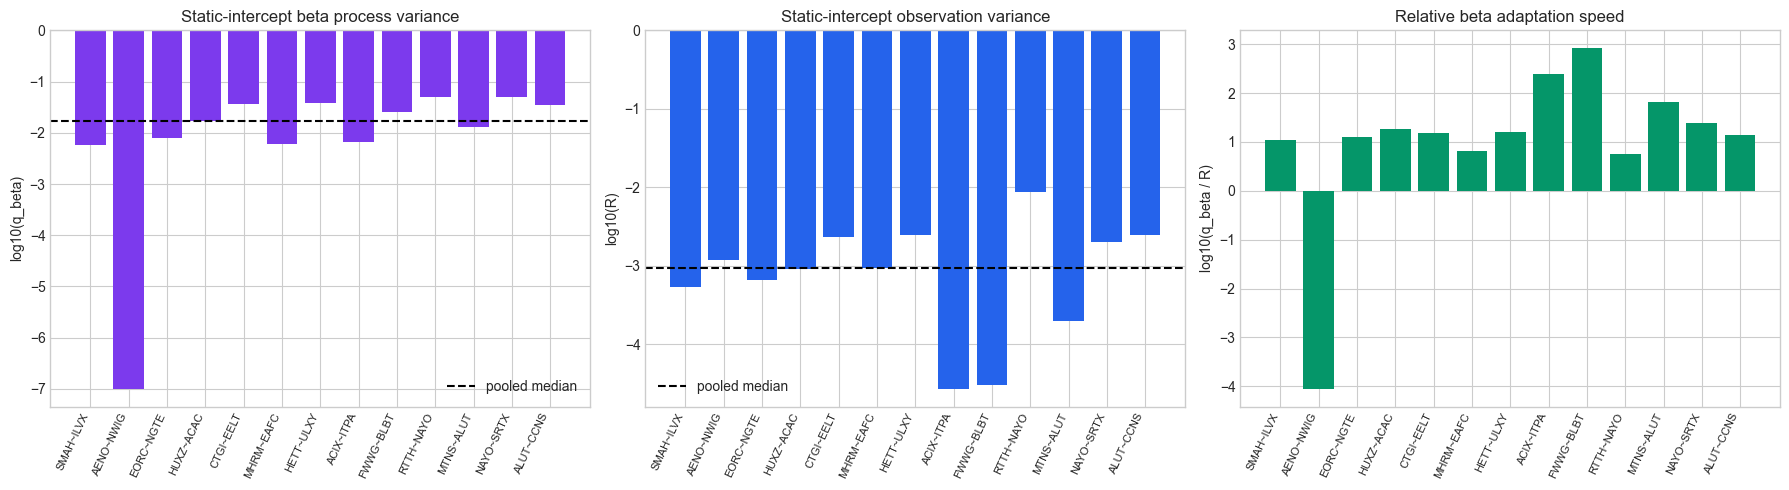

In [6]:

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
xpos = np.arange(len(parameters))

axes[0].bar(xpos, np.log10(parameters.beta_only_q_beta), color="#7c3aed")
axes[0].axhline(np.log10(pooled_beta_only["q_beta"]), color="black", ls="--", label="pooled median")
axes[0].set_title("Static-intercept beta process variance")
axes[0].set_ylabel("log10(q_beta)")
axes[0].legend()

axes[1].bar(xpos, np.log10(parameters.beta_only_R), color="#2563eb")
axes[1].axhline(np.log10(pooled_beta_only["R"]), color="black", ls="--", label="pooled median")
axes[1].set_title("Static-intercept observation variance")
axes[1].set_ylabel("log10(R)")
axes[1].legend()

axes[2].bar(xpos, np.log10(parameters.beta_only_q_over_R), color="#059669")
axes[2].set_title("Relative beta adaptation speed")
axes[2].set_ylabel("log10(q_beta / R)")

for ax in axes:
    ax.set_xticks(xpos)
    ax.set_xticklabels(parameters.pair, rotation=65, ha="right", fontsize=8)

fig.tight_layout()
fig.savefig(OUT_DIR / "pair_specific_kalman_parameters.png", dpi=160, bbox_inches="tight")
plt.show()


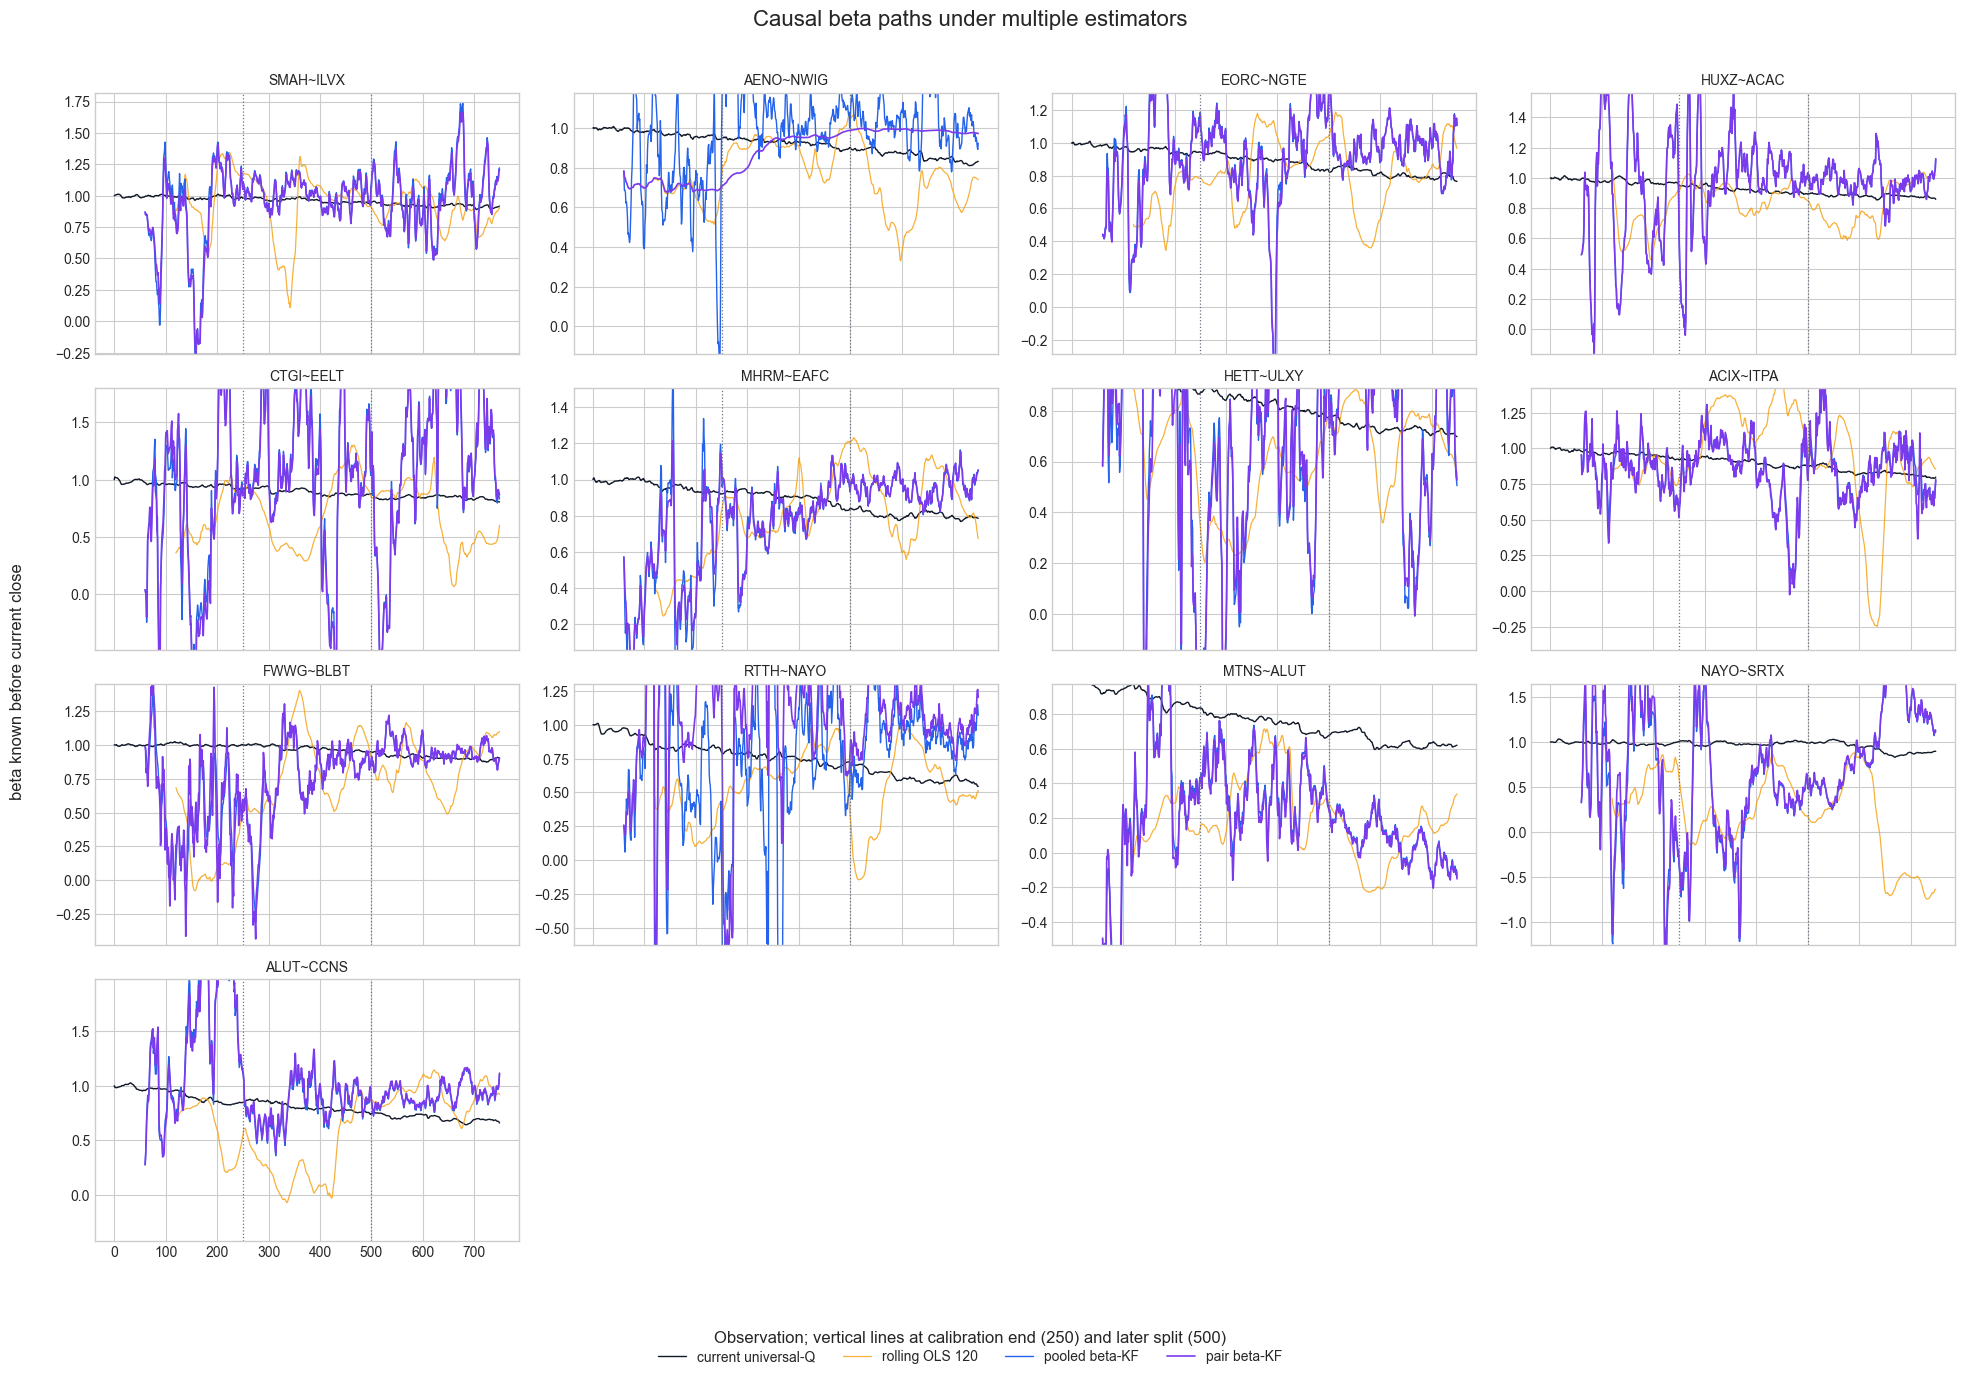

In [7]:

fig, axes = plt.subplots(4, 4, figsize=(20, 14), sharex=True)
axes = axes.ravel()
for ax, (label, data) in zip(axes, pair_data.items()):
    days = np.arange(n_days)
    ax.plot(days, data["current"]["beta"], color="#111827", lw=1.0, label="current universal-Q")
    ax.plot(days, data["rolling_120"]["beta"], color="#f59e0b", lw=0.9, alpha=0.8, label="rolling OLS 120")
    ax.plot(days, data["pooled_beta_kf"]["beta"], color="#2563eb", lw=1.0, label="pooled beta-KF")
    ax.plot(days, data["pair_beta_kf"]["beta"], color="#7c3aed", lw=1.2, label="pair beta-KF")
    ax.axvline(CALIBRATION_END, color="#6b7280", ls=":", lw=0.9)
    ax.axvline(500, color="#6b7280", ls=":", lw=0.9)
    ax.set_title(label, fontsize=10)
    ax.set_ylim(np.nanpercentile(data["rolling_60"]["beta"], 1) - 0.05,
                np.nanpercentile(data["rolling_60"]["beta"], 99) + 0.05)
for ax in axes[len(pair_data):]:
    ax.axis("off")
handles, labels_ = axes[0].get_legend_handles_labels()
fig.legend(handles, labels_, loc="lower center", bbox_to_anchor=(0.5, 0.004),
           ncol=4, frameon=False)
fig.suptitle("Causal beta paths under multiple estimators", fontsize=16)
fig.supxlabel("Observation; vertical lines at calibration end (250) and later split (500)", y=0.026)
fig.supylabel("beta known before current close")
fig.tight_layout(rect=[0.02, 0.055, 1, 0.97])
fig.savefig(OUT_DIR / "all_pair_dynamic_beta_paths.png", dpi=160, bbox_inches="tight")
plt.show()


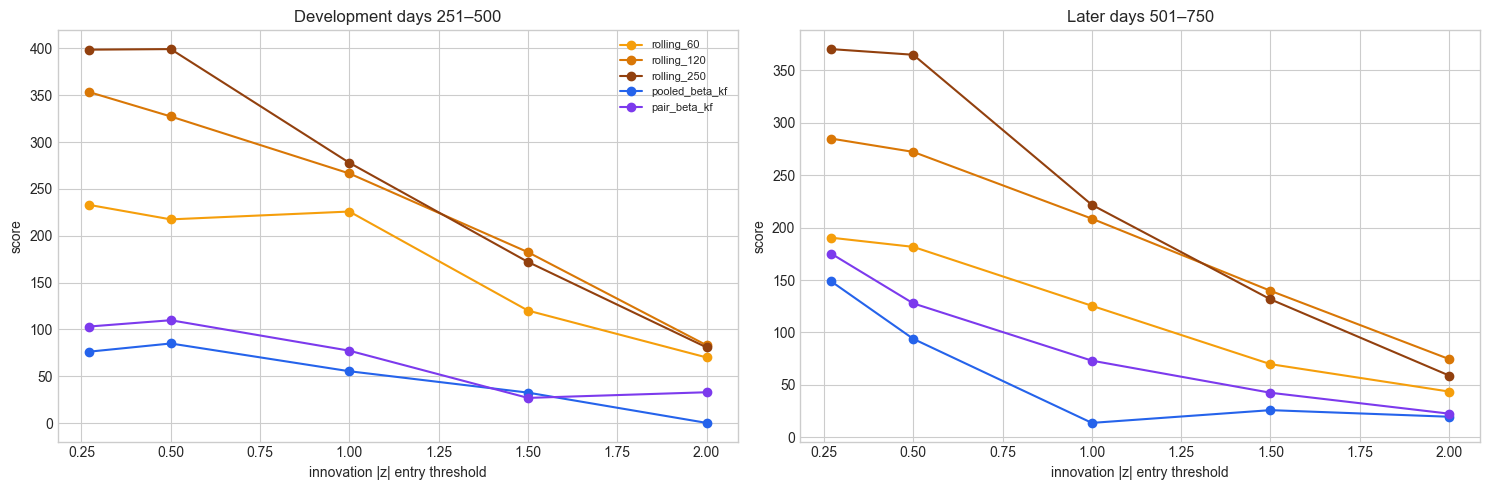

In [8]:

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for method, color in [("rolling_60", "#f59e0b"), ("rolling_120", "#d97706"),
                      ("rolling_250", "#92400e"), ("pooled_beta_kf", "#2563eb"),
                      ("pair_beta_kf", "#7c3aed")]:
    subset = trades[(trades.method == method) & (trades.sizing == "dynamic_beta")]
    for ax, period, title in [
        (axes[0], "development_251_500", "Development days 251–500"),
        (axes[1], "later_501_750", "Later days 501–750"),
    ]:
        values = subset[subset.period == period].sort_values("threshold")
        ax.plot(values.threshold, values.score, marker="o", label=method, color=color)
        ax.set_title(title)
        ax.set_xlabel("innovation |z| entry threshold")
        ax.set_ylabel("score")
axes[0].legend(fontsize=8)
fig.tight_layout()
fig.savefig(OUT_DIR / "dynamic_beta_threshold_robustness.png", dpi=160, bbox_inches="tight")
plt.show()



## Pair-by-pair multiple-beta diagnostics

Each section compares beta paths, exact-current versus rolling-250 deviation scores, and cumulative standalone PnL. The rolling threshold is selected once from aggregate development performance, not separately for each pair. Pair-specific Kalman tracking statistics remain in the table so its rejected high-gain behaviour is visible.


### 1. SMAH~ILVX

pair,SMAH~ILVX
q_alpha,0.000395
q_beta,0.0
R,0.000027
q_beta_over_R,0.005215
q_alpha_over_R,14.875154
optimizer_success,True
calibration_nll,-635.427805
beta_only_q_beta,0.005773
beta_only_R,0.00054
beta_only_q_over_R,10.696513


,innovation_RMSE,predictive_NLL_per_obs,innovation_lag1_corr,beta_daily_abs_change
method,,,,
current,0.024692,-3.194431,0.509599,0.001833
rolling_60,0.045812,-2.534968,0.878328,0.018426
rolling_120,0.044940,-2.578067,0.882919,0.006647
rolling_250,0.044581,-2.601314,0.876962,0.001939
pooled_kf,0.020282,-3.397975,0.037419,0.001077
pair_kf,0.020338,-3.393727,0.081632,0.001076
pooled_beta_kf,0.023593,-2.806057,0.377300,0.036223
pair_beta_kf,0.024374,-3.050699,0.449293,0.032121


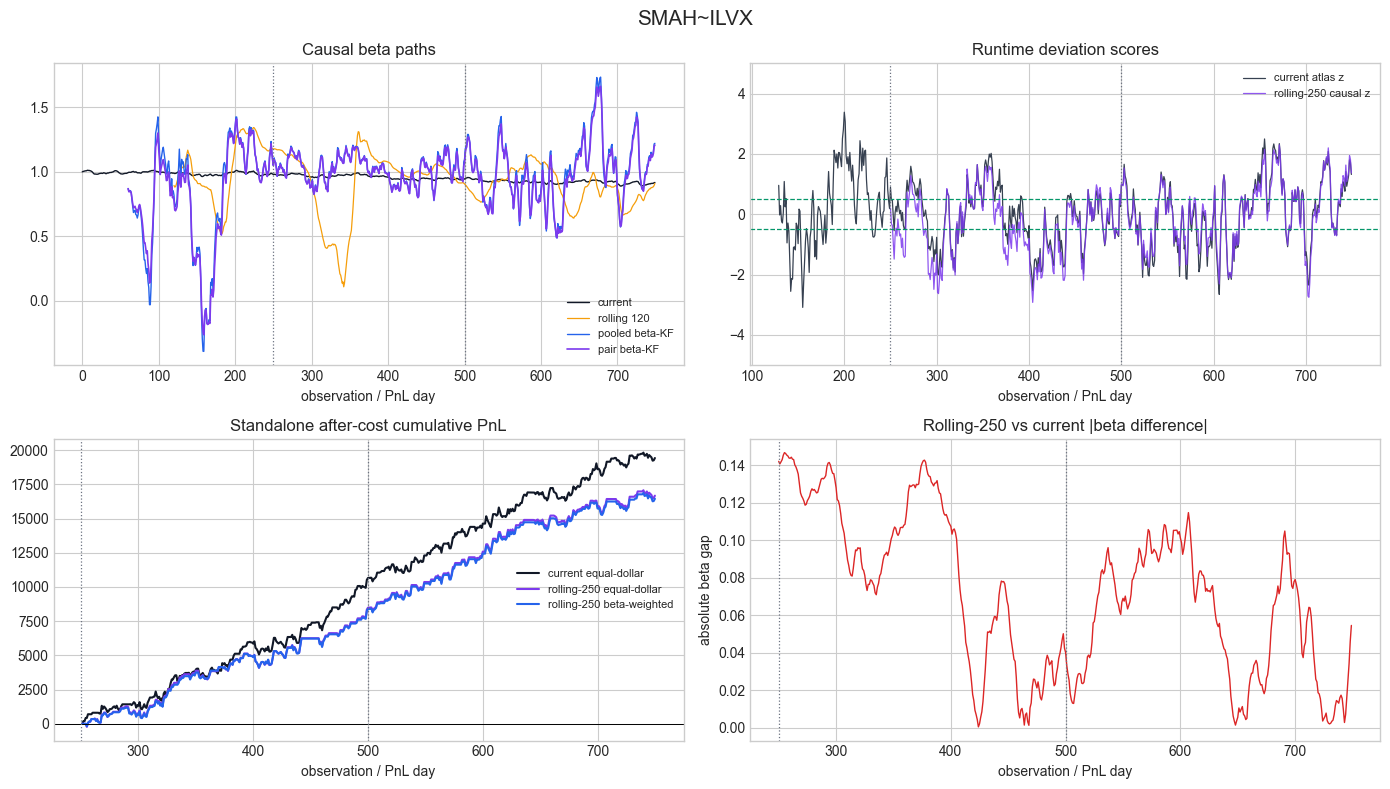

### 2. AENO~NWIG

pair,AENO~NWIG
q_alpha,0.000269
q_beta,0.001335
R,0.000032
q_beta_over_R,41.259327
q_alpha_over_R,8.321836
optimizer_success,True
calibration_nll,-655.707349
beta_only_q_beta,0.0
beta_only_R,0.001165
beta_only_q_over_R,0.000086


,innovation_RMSE,predictive_NLL_per_obs,innovation_lag1_corr,beta_daily_abs_change
method,,,,
current,0.025555,-3.101741,0.507193,0.001413
rolling_60,0.043240,-2.525197,0.882151,0.011017
rolling_120,0.045637,-2.548675,0.889619,0.004736
rolling_250,0.047701,-2.509976,0.888946,0.001613
pooled_kf,0.017505,-3.526591,-0.038725,0.000486
pair_kf,0.017325,-3.431488,0.005888,0.010111
pooled_beta_kf,0.026053,-2.569449,0.257305,0.028156
pair_beta_kf,0.049712,-2.321482,0.883219,0.000550


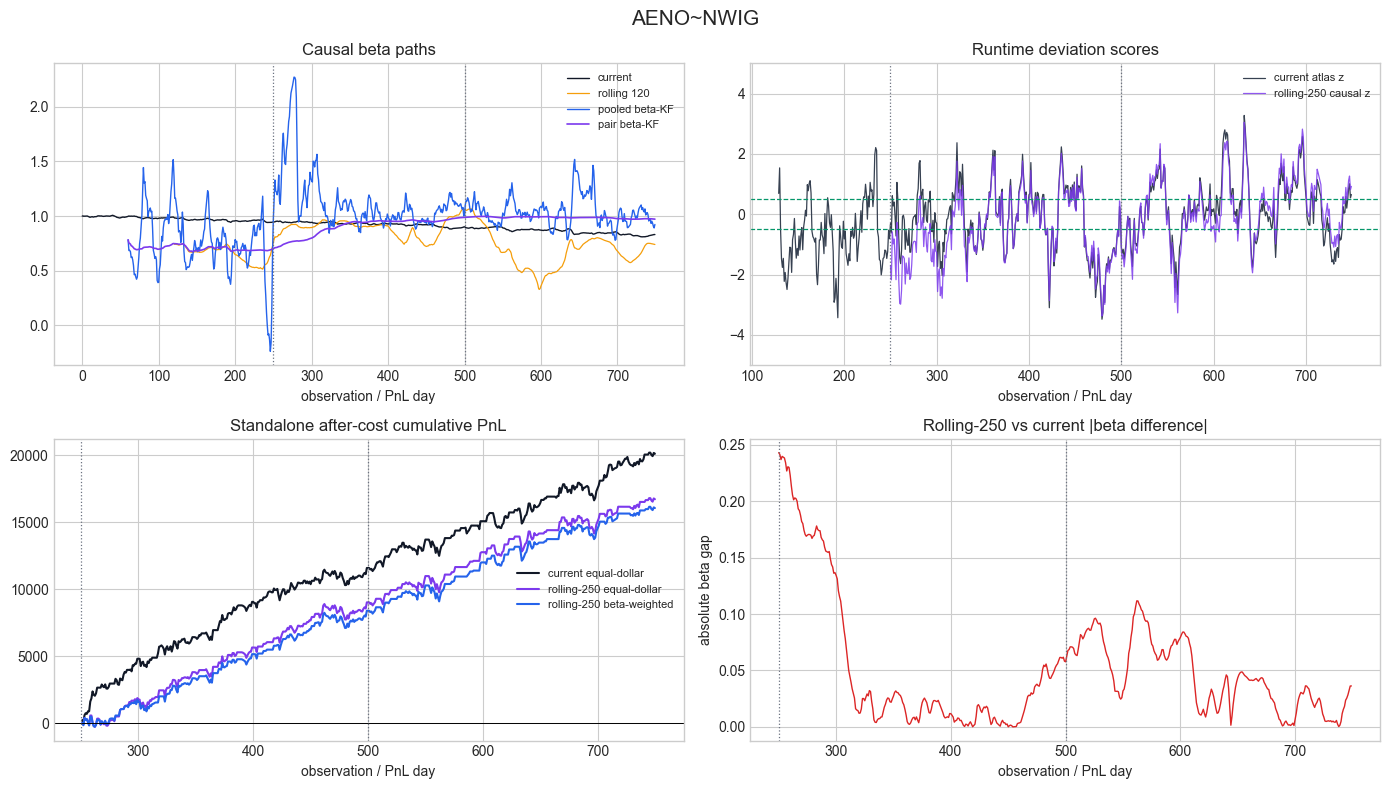

### 3. EORC~NGTE

pair,EORC~NGTE
q_alpha,0.000412
q_beta,0.0
R,0.000019
q_beta_over_R,0.003231
q_alpha_over_R,21.8755
optimizer_success,True
calibration_nll,-635.790156
beta_only_q_beta,0.008014
beta_only_R,0.00065
beta_only_q_over_R,12.336727


,innovation_RMSE,predictive_NLL_per_obs,innovation_lag1_corr,beta_daily_abs_change
method,,,,
current,0.029024,-3.027092,0.479424,0.001636
rolling_60,0.055753,-2.239744,0.878500,0.014767
rolling_120,0.060275,-2.273926,0.903651,0.006259
rolling_250,0.059359,-2.315676,0.899597,0.001756
pooled_kf,0.021839,-3.317770,-0.053507,0.000548
pair_kf,0.021824,-3.324034,-0.028572,0.000514
pooled_beta_kf,0.027849,-2.639401,0.166925,0.033218
pair_beta_kf,0.028239,-2.833858,0.227323,0.031688


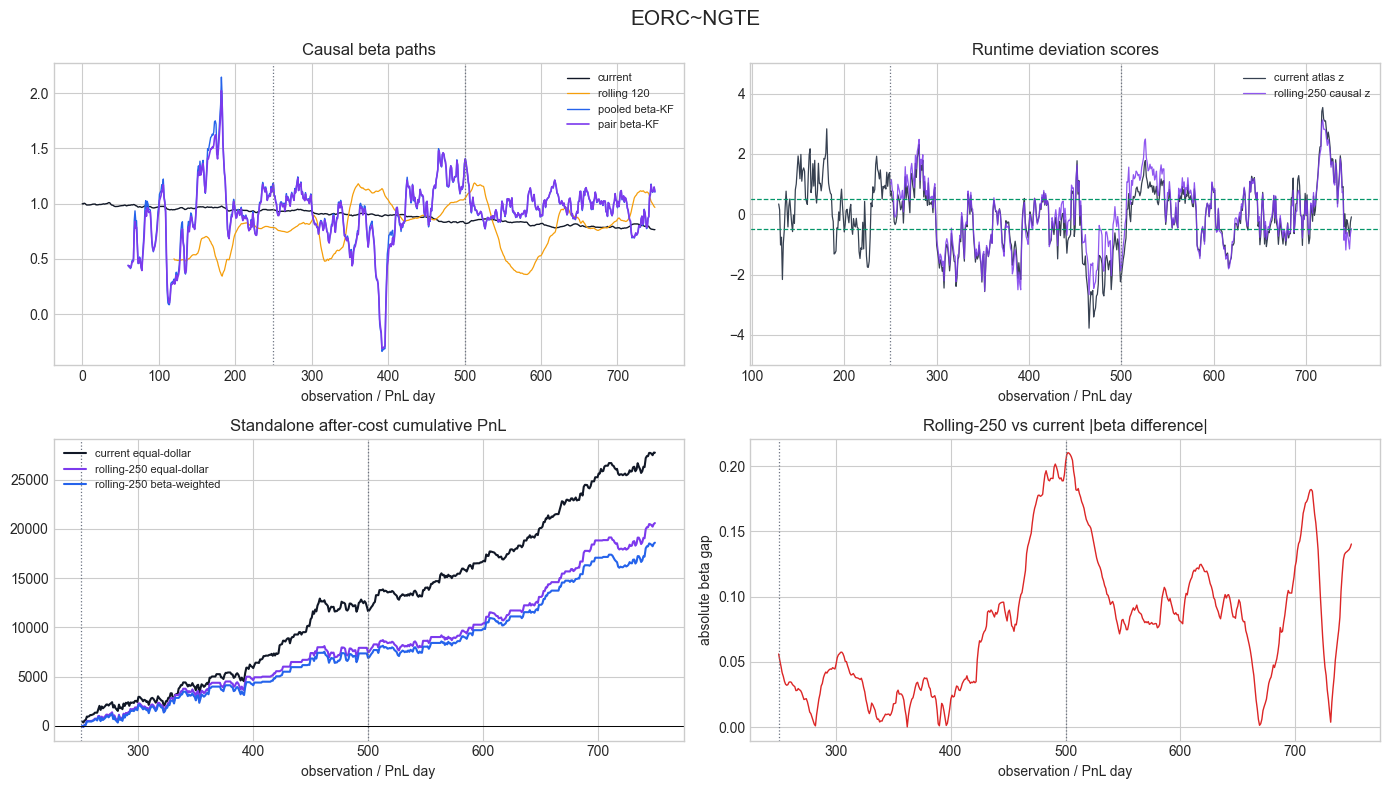

### 4. HUXZ~ACAC

pair,HUXZ~ACAC
q_alpha,0.000404
q_beta,0.0
R,0.000008
q_beta_over_R,0.015873
q_alpha_over_R,50.503204
optimizer_success,True
calibration_nll,-642.130641
beta_only_q_beta,0.016931
beta_only_R,0.000907
beta_only_q_over_R,18.666049


,innovation_RMSE,predictive_NLL_per_obs,innovation_lag1_corr,beta_daily_abs_change
method,,,,
current,0.027242,-3.053786,0.545864,0.001483
rolling_60,0.043897,-2.614584,0.860852,0.014958
rolling_120,0.044158,-2.619321,0.864250,0.004318
rolling_250,0.047198,-2.564323,0.877358,0.001862
pooled_kf,0.021030,-3.360109,-0.065323,0.000979
pair_kf,0.021023,-3.361439,-0.061479,0.000973
pooled_beta_kf,0.027414,-2.584354,0.349896,0.032009
pair_beta_kf,0.027375,-2.586756,0.347106,0.031981


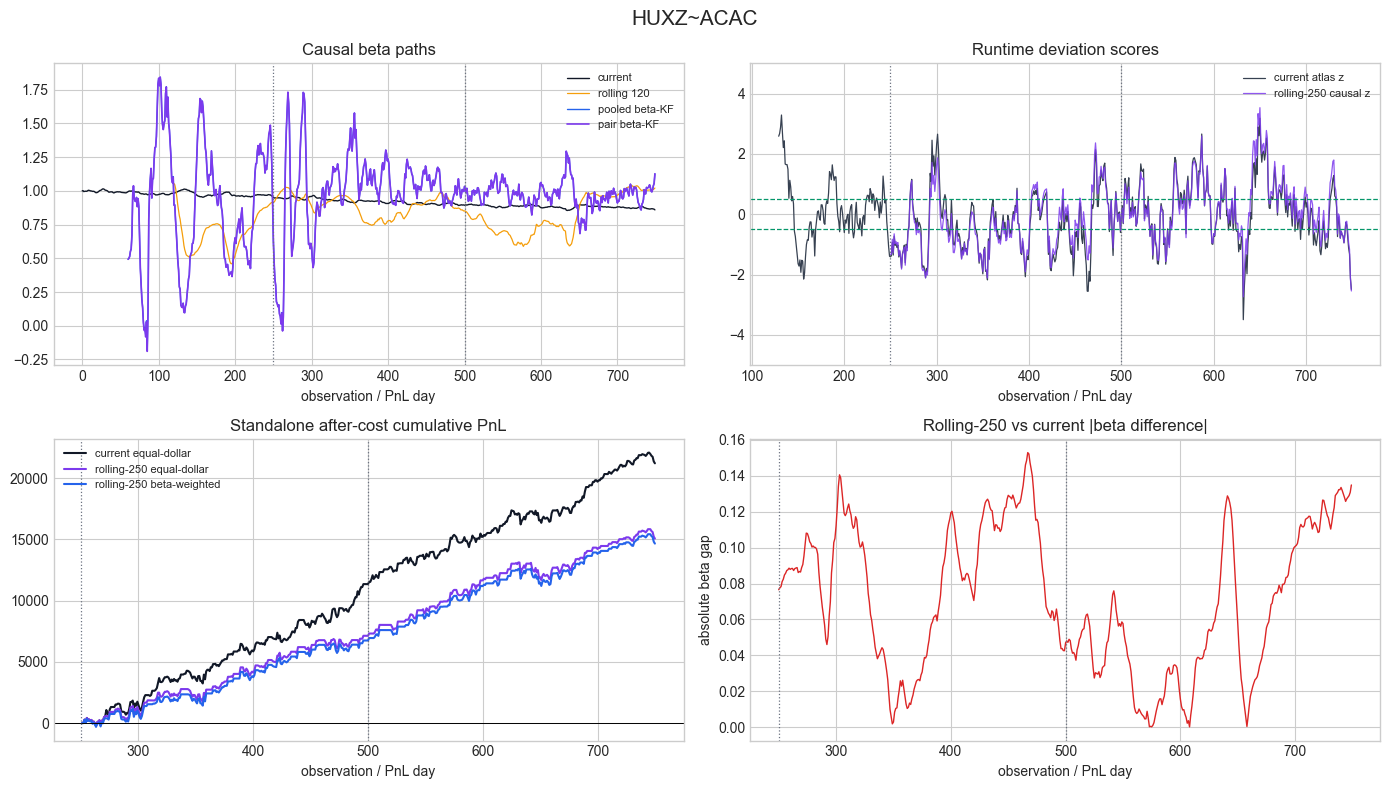

### 5. CTGI~EELT

pair,CTGI~EELT
q_alpha,0.000934
q_beta,0.0
R,0.0
q_beta_over_R,0.945757
q_alpha_over_R,61316.154572
optimizer_success,True
calibration_nll,-566.999644
beta_only_q_beta,0.035744
beta_only_R,0.002305
beta_only_q_over_R,15.506248


,innovation_RMSE,predictive_NLL_per_obs,innovation_lag1_corr,beta_daily_abs_change
method,,,,
current,0.045025,-2.597335,0.592986,0.001725
rolling_60,0.077890,-1.959632,0.891240,0.018044
rolling_120,0.090008,-1.823086,0.922193,0.007882
rolling_250,0.093099,-1.853014,0.911812,0.002644
pooled_kf,0.029115,-2.863430,-0.040174,0.000694
pair_kf,0.029175,-3.032170,-0.058075,0.000561
pooled_beta_kf,0.060732,-1.793999,0.592795,0.097332
pair_beta_kf,0.060566,-2.158723,0.605283,0.090175


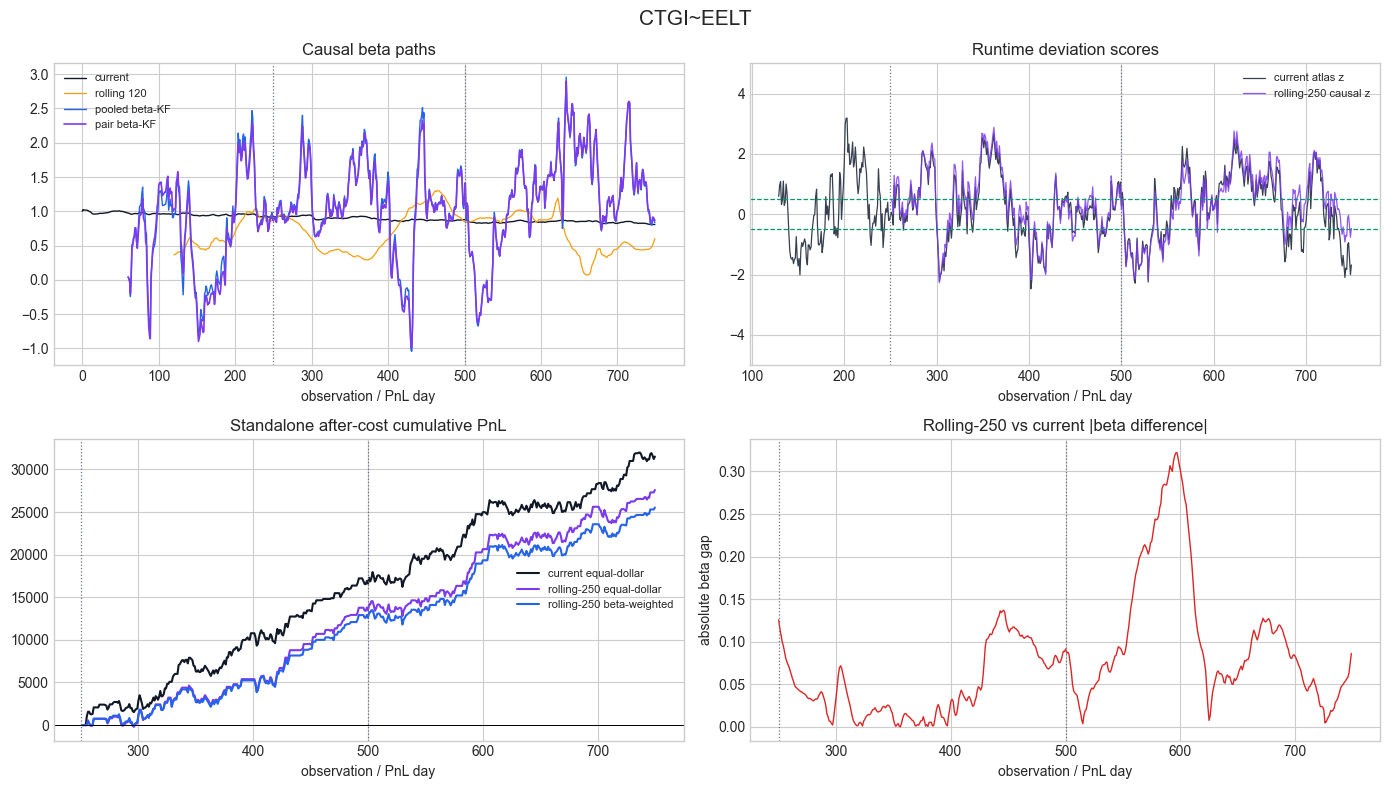

### 6. MHRM~EAFC

pair,MHRM~EAFC
q_alpha,0.000411
q_beta,0.0
R,0.000049
q_beta_over_R,0.000001
q_alpha_over_R,8.387777
optimizer_success,True
calibration_nll,-625.173162
beta_only_q_beta,0.006002
beta_only_R,0.000925
beta_only_q_over_R,6.487262


,innovation_RMSE,predictive_NLL_per_obs,innovation_lag1_corr,beta_daily_abs_change
method,,,,
current,0.027984,-3.049938,0.575583,0.001599
rolling_60,0.044411,-2.537083,0.850034,0.013326
rolling_120,0.048075,-2.497689,0.871383,0.005750
rolling_250,0.049602,-2.487427,0.873199,0.001579
pooled_kf,0.020844,-3.369607,-0.020209,0.000442
pair_kf,0.020873,-3.364172,0.053256,0.000360
pooled_beta_kf,0.023764,-2.462178,0.094815,0.025509
pair_beta_kf,0.024253,-2.747071,0.213551,0.021909


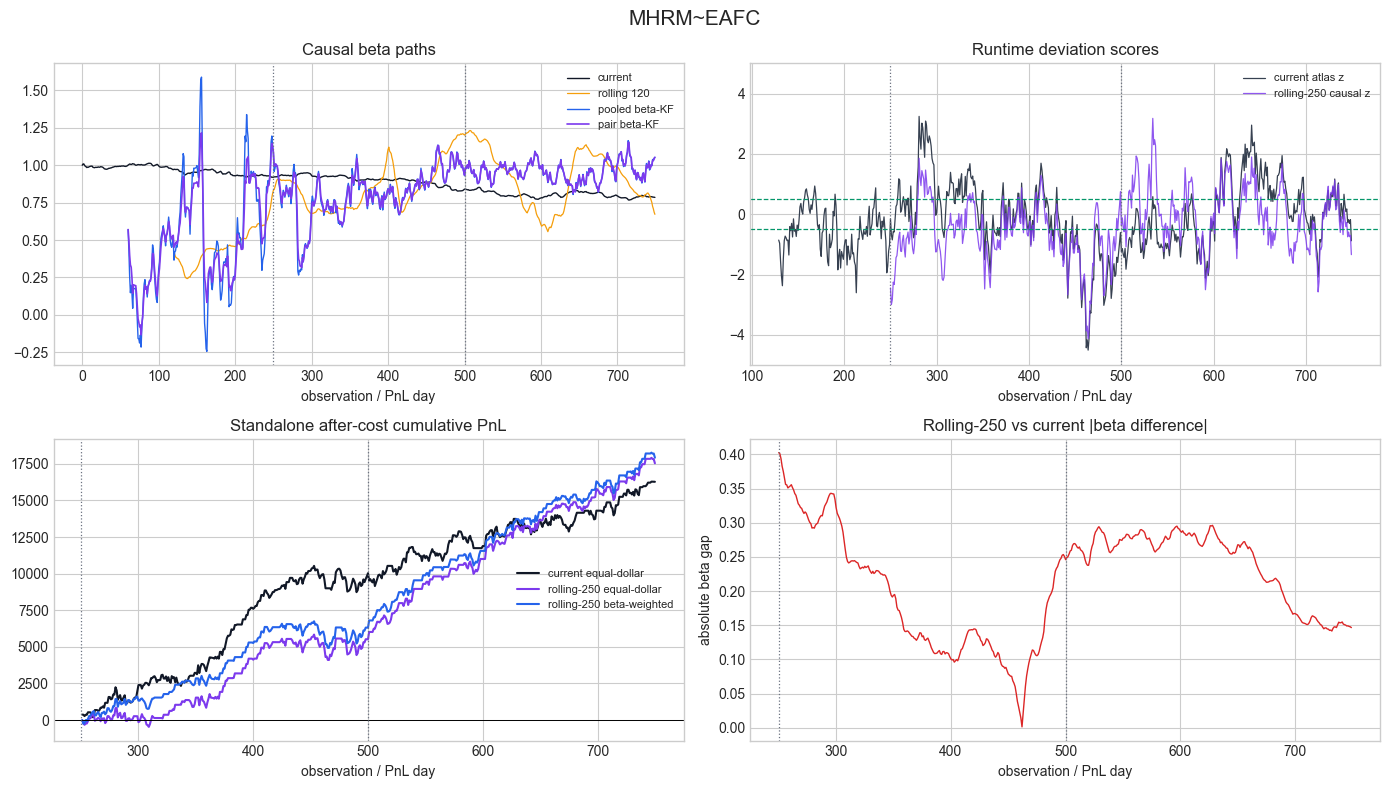

### 7. HETT~ULXY

pair,HETT~ULXY
q_alpha,0.000267
q_beta,0.000852
R,0.0
q_beta_over_R,55958.411838
q_alpha_over_R,17530.964712
optimizer_success,True
calibration_nll,-675.7541
beta_only_q_beta,0.038091
beta_only_R,0.002435
beta_only_q_over_R,15.644285


,innovation_RMSE,predictive_NLL_per_obs,innovation_lag1_corr,beta_daily_abs_change
method,,,,
current,0.030070,-2.932592,0.573457,0.001528
rolling_60,0.043941,-2.474925,0.906116,0.009929
rolling_120,0.052428,-2.391089,0.914594,0.004801
rolling_250,0.053833,-2.391963,0.901447,0.001971
pooled_kf,0.014602,-3.640608,0.031591,0.000363
pair_kf,0.014743,-3.694284,0.018012,0.008499
pooled_beta_kf,0.034232,-2.806735,0.602966,0.060484
pair_beta_kf,0.034504,-2.608822,0.618046,0.058180


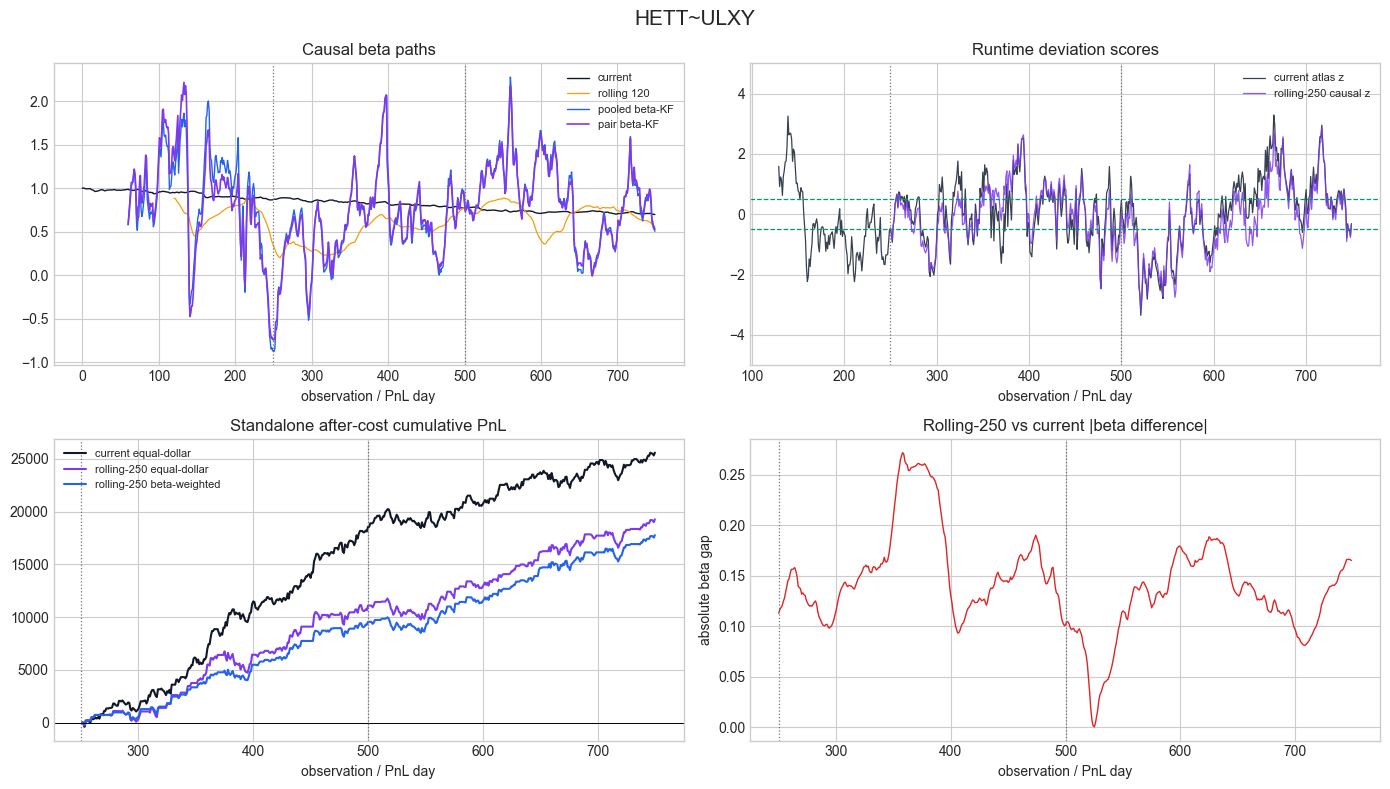

### 8. ACIX~ITPA

pair,ACIX~ITPA
q_alpha,0.000166
q_beta,0.000942
R,0.0
q_beta_over_R,61882.455043
q_alpha_over_R,10879.423939
optimizer_success,True
calibration_nll,-710.562243
beta_only_q_beta,0.006511
beta_only_R,0.000027
beta_only_q_over_R,241.08084


,innovation_RMSE,predictive_NLL_per_obs,innovation_lag1_corr,beta_daily_abs_change
method,,,,
current,0.018429,-3.451510,0.465452,0.001533
rolling_60,0.045294,-2.512587,0.924340,0.018569
rolling_120,0.053608,-2.371500,0.940679,0.008531
rolling_250,0.048854,-2.463456,0.930171,0.002920
pooled_kf,0.015391,-3.611852,-0.045224,0.000585
pair_kf,0.015209,-3.679380,-0.053395,0.011583
pooled_beta_kf,0.017600,-2.932631,0.313517,0.030441
pair_beta_kf,0.016717,-3.483483,0.003689,0.044431


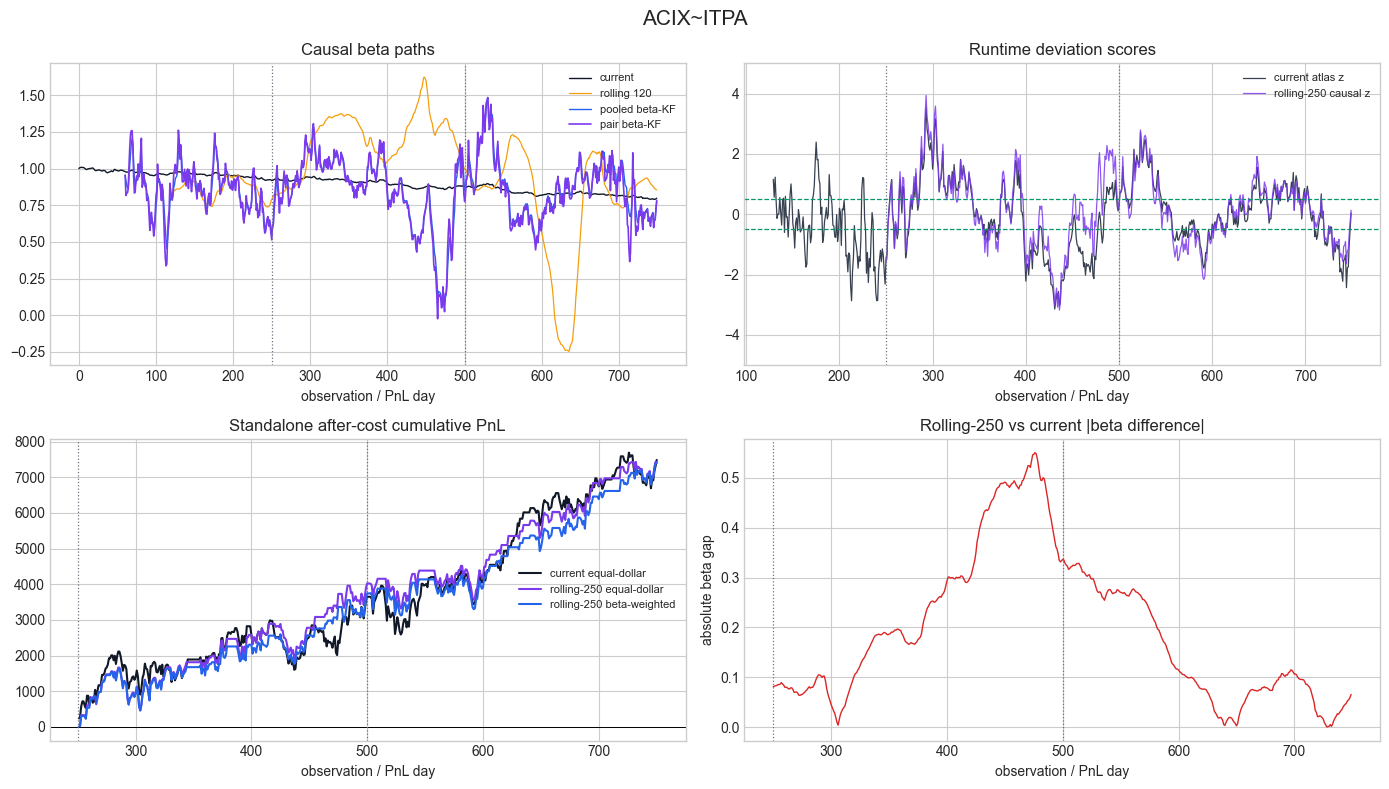

### 9. FWWG~BLBT

pair,FWWG~BLBT
q_alpha,0.000167
q_beta,0.001631
R,0.000006
q_beta_over_R,256.032116
q_alpha_over_R,26.209148
optimizer_success,True
calibration_nll,-714.73575
beta_only_q_beta,0.025635
beta_only_R,0.00003
beta_only_q_over_R,852.142964


,innovation_RMSE,predictive_NLL_per_obs,innovation_lag1_corr,beta_daily_abs_change
method,,,,
current,0.017566,-3.489330,0.468125,0.001465
rolling_60,0.039002,-2.724329,0.912807,0.018441
rolling_120,0.042097,-2.594679,0.929496,0.009610
rolling_250,0.042763,-2.620570,0.928724,0.003070
pooled_kf,0.015201,-3.619176,0.021369,0.000254
pair_kf,0.014123,-3.627008,0.036472,0.011935
pooled_beta_kf,0.016422,-2.724166,0.303556,0.022262
pair_beta_kf,0.015467,-2.824211,0.032635,0.028200


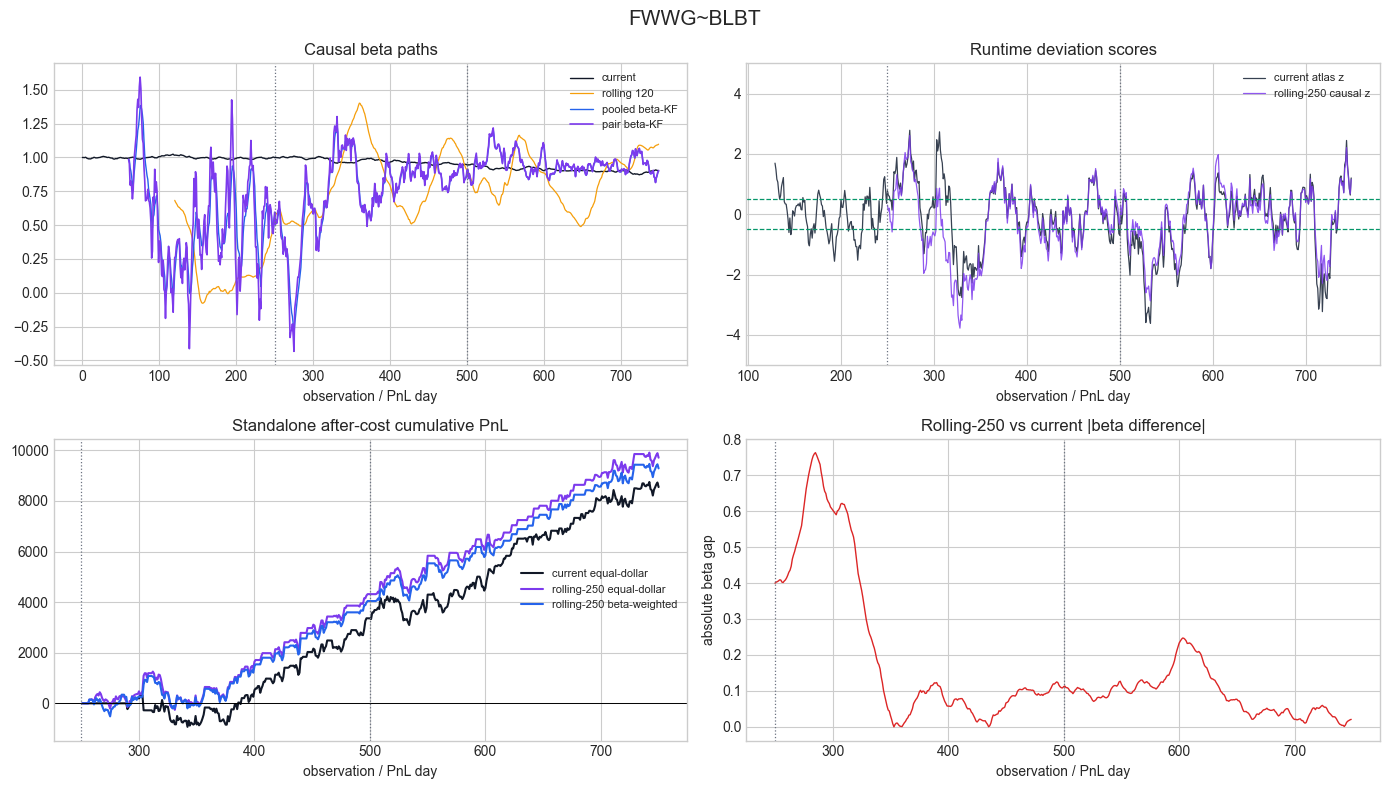

### 10. RTTH~NAYO

pair,RTTH~NAYO
q_alpha,0.001095
q_beta,0.0
R,0.0
q_beta_over_R,0.026072
q_alpha_over_R,71930.062938
optimizer_success,True
calibration_nll,-552.242572
beta_only_q_beta,0.049787
beta_only_R,0.008817
beta_only_q_over_R,5.646425


,innovation_RMSE,predictive_NLL_per_obs,innovation_lag1_corr,beta_daily_abs_change
method,,,,
current,0.047859,-2.509015,0.659040,0.002059
rolling_60,0.078297,-1.990876,0.888410,0.016301
rolling_120,0.084935,-1.918724,0.903970,0.006234
rolling_250,0.086340,-1.920885,0.900544,0.003072
pooled_kf,0.031578,-2.681043,0.004347,0.000793
pair_kf,0.031581,-2.952998,-0.011304,0.000679
pooled_beta_kf,0.048540,-2.224199,0.377811,0.056823
pair_beta_kf,0.062506,-1.793953,0.563688,0.048891


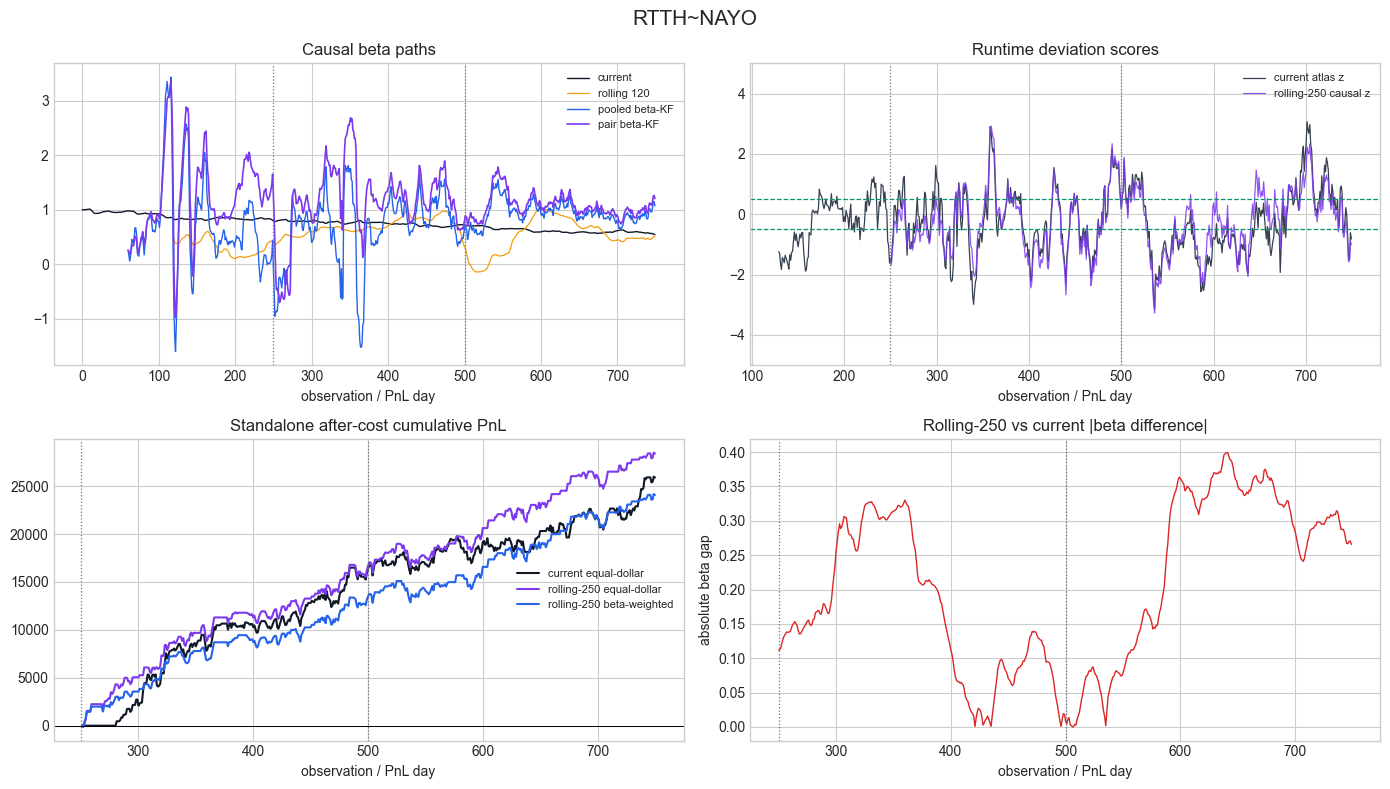

### 11. MTNS~ALUT

pair,MTNS~ALUT
q_alpha,0.000384
q_beta,0.000397
R,0.000006
q_beta_over_R,64.960563
q_alpha_over_R,62.797052
optimizer_success,True
calibration_nll,-642.484525
beta_only_q_beta,0.012864
beta_only_R,0.000195
beta_only_q_over_R,65.922702


,innovation_RMSE,predictive_NLL_per_obs,innovation_lag1_corr,beta_daily_abs_change
method,,,,
current,0.031347,-2.962461,0.717853,0.001524
rolling_60,0.049683,-2.415811,0.912467,0.012345
rolling_120,0.055332,-2.394238,0.925995,0.005914
rolling_250,0.067568,-2.196197,0.949003,0.002499
pooled_kf,0.018548,-3.480476,0.013057,0.000687
pair_kf,0.018479,-3.454889,0.003658,0.006201
pooled_beta_kf,0.019792,-2.618531,0.273713,0.025124
pair_beta_kf,0.019051,-2.880102,0.136513,0.028602


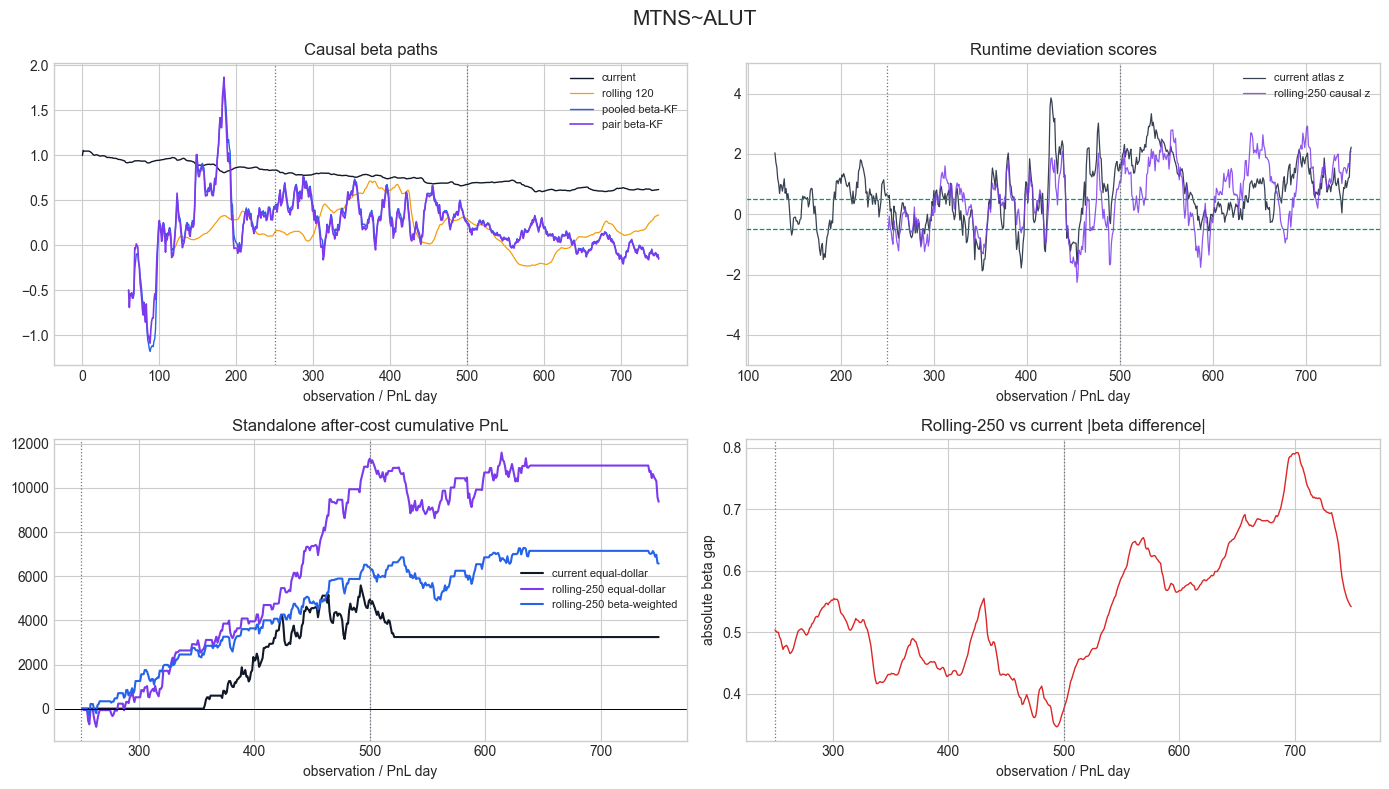

### 12. NAYO~SRTX

pair,NAYO~SRTX
q_alpha,0.001032
q_beta,0.000001
R,0.0
q_beta_over_R,36.291441
q_alpha_over_R,67780.47939
optimizer_success,True
calibration_nll,-557.666268
beta_only_q_beta,0.049787
beta_only_R,0.002027
beta_only_q_over_R,24.556074


,innovation_RMSE,predictive_NLL_per_obs,innovation_lag1_corr,beta_daily_abs_change
method,,,,
current,0.045243,-2.592166,0.643678,0.001913
rolling_60,0.103871,-1.664696,0.933882,0.030619
rolling_120,0.107044,-1.731757,0.945802,0.010332
rolling_250,0.165525,-1.314674,0.974789,0.003973
pooled_kf,0.032063,-2.642942,-0.008807,0.001336
pair_kf,0.032047,-2.940539,-0.022130,0.001107
pooled_beta_kf,0.039409,-2.432364,0.361374,0.048074
pair_beta_kf,0.038987,-2.133739,0.323437,0.048232


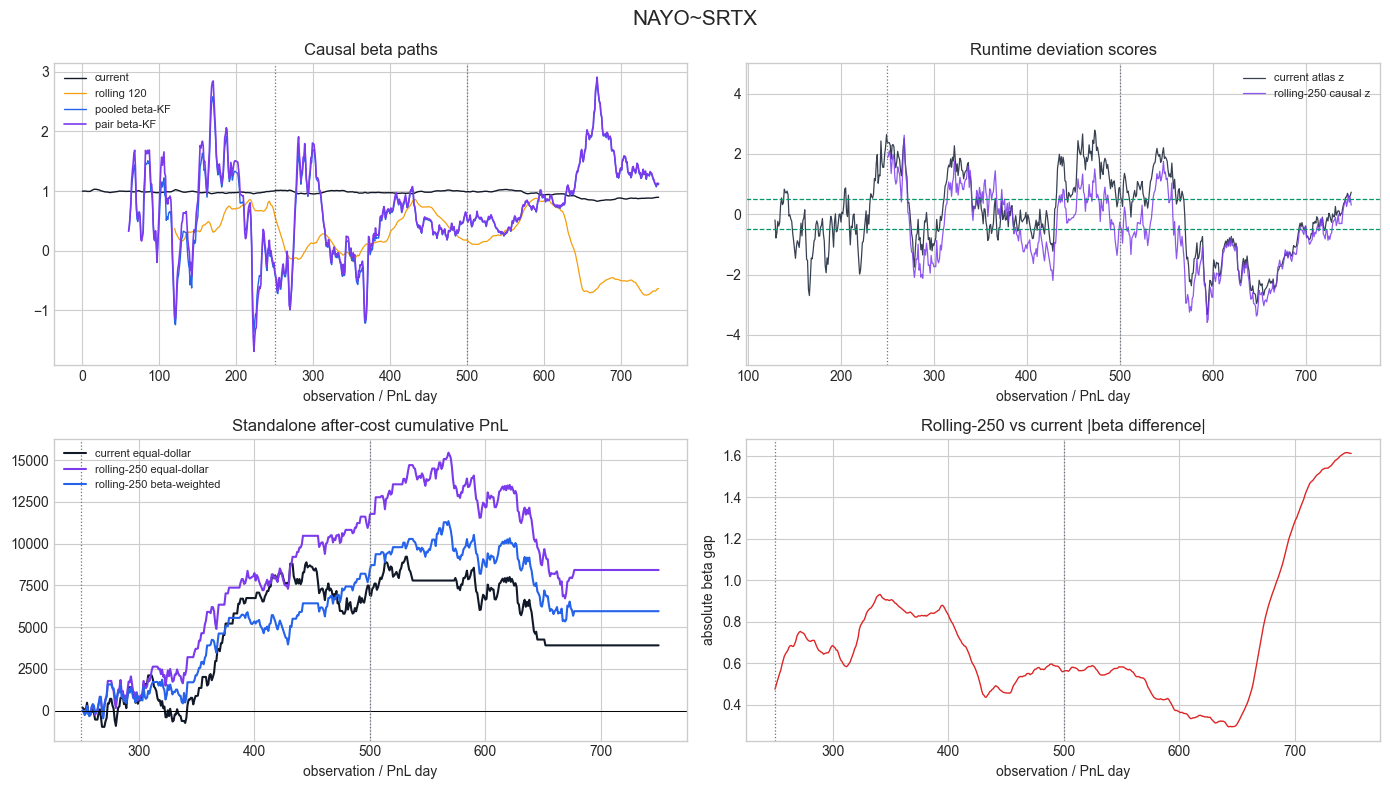

### 13. ALUT~CCNS

pair,ALUT~CCNS
q_alpha,0.00039
q_beta,0.0
R,0.0
q_beta_over_R,0.002639
q_alpha_over_R,25579.687254
optimizer_success,True
calibration_nll,-650.306979
beta_only_q_beta,0.034776
beta_only_R,0.002478
beta_only_q_over_R,14.031581


,innovation_RMSE,predictive_NLL_per_obs,innovation_lag1_corr,beta_daily_abs_change
method,,,,
current,0.031333,-2.960925,0.653150,0.001856
rolling_60,0.060573,-2.224988,0.912157,0.022999
rolling_120,0.063846,-2.210514,0.932138,0.007585
rolling_250,0.067101,-2.181478,0.939461,0.002441
pooled_kf,0.020697,-3.377130,0.096265,0.000572
pair_kf,0.020670,-3.376936,0.082186,0.000559
pooled_beta_kf,0.025192,-2.536245,0.209240,0.032054
pair_beta_kf,0.025621,-2.172544,0.239396,0.030972


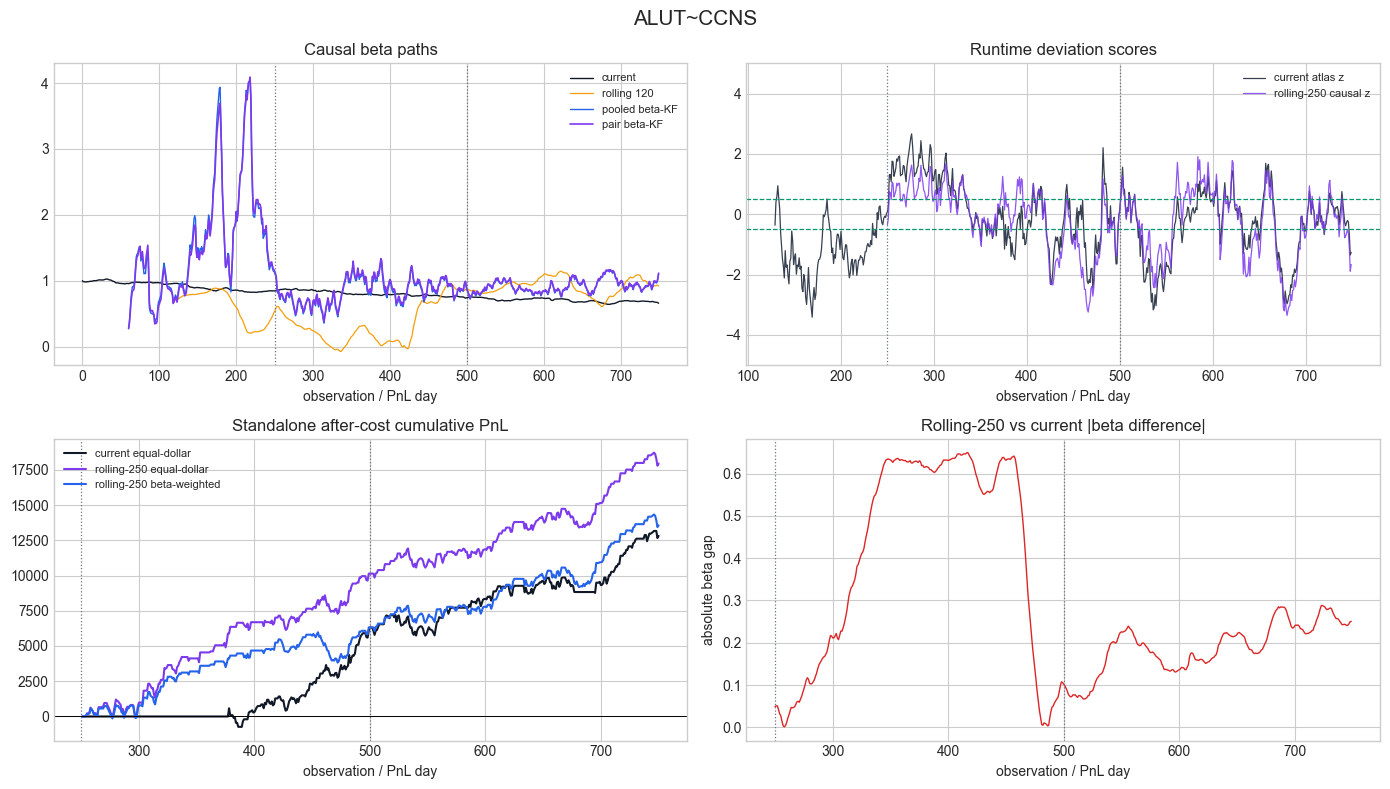

In [9]:

chosen_pair_threshold = rolling250_threshold

for number, (label, data) in enumerate(pair_data.items(), start=1):
    display(Markdown(f"### {number}. {label}"))
    parameter_view = parameters[parameters.pair == label].set_index("pair").T
    pair_tracking = tracking[tracking.pair == label].set_index("method")[[
        "innovation_RMSE", "predictive_NLL_per_obs", "innovation_lag1_corr",
        "beta_daily_abs_change"
    ]]
    display(parameter_view.round(10))
    display(pair_tracking.round(6))

    current_pnl, _, _ = backtest_pair(data, "current", np.nan, "equal")
    rolling_pnl, _, _ = backtest_pair(data, "rolling_250", chosen_pair_threshold, "equal")
    rolling_beta_pnl, _, _ = backtest_pair(data, "rolling_250", chosen_pair_threshold, "dynamic_beta")
    days = np.arange(n_days)

    fig, axes = plt.subplots(2, 2, figsize=(14, 8))
    axes[0, 0].plot(days, data["current"]["beta"], color="#111827", lw=1.0, label="current")
    axes[0, 0].plot(days, data["rolling_120"]["beta"], color="#f59e0b", lw=0.9, label="rolling 120")
    axes[0, 0].plot(days, data["pooled_beta_kf"]["beta"], color="#2563eb", lw=1.0, label="pooled beta-KF")
    axes[0, 0].plot(days, data["pair_beta_kf"]["beta"], color="#7c3aed", lw=1.2, label="pair beta-KF")
    axes[0, 0].set_title("Causal beta paths")
    axes[0, 0].legend(fontsize=8)

    axes[0, 1].plot(days, data["current"]["z"], color="#374151", lw=0.9, label="current atlas z")
    axes[0, 1].plot(days, data["rolling_250"]["z"], color="#7c3aed", lw=0.9, alpha=0.85, label="rolling-250 causal z")
    axes[0, 1].axhline(chosen_pair_threshold, color="#059669", ls="--", lw=0.9)
    axes[0, 1].axhline(-chosen_pair_threshold, color="#059669", ls="--", lw=0.9)
    axes[0, 1].set_ylim(-5, 5)
    axes[0, 1].set_title("Runtime deviation scores")
    axes[0, 1].legend(fontsize=8)

    axes[1, 0].plot(np.arange(251, 751), np.cumsum(current_pnl), color="#111827", label="current equal-dollar")
    axes[1, 0].plot(np.arange(251, 751), np.cumsum(rolling_pnl), color="#7c3aed", label="rolling-250 equal-dollar")
    axes[1, 0].plot(np.arange(251, 751), np.cumsum(rolling_beta_pnl), color="#2563eb", label="rolling-250 beta-weighted")
    axes[1, 0].axhline(0, color="black", lw=0.7)
    axes[1, 0].set_title("Standalone after-cost cumulative PnL")
    axes[1, 0].legend(fontsize=8)

    beta_gap = np.abs(data["rolling_250"]["beta"] - data["current"]["beta"])
    axes[1, 1].plot(days, beta_gap, color="#dc2626", lw=1.0)
    axes[1, 1].set_title("Rolling-250 vs current |beta difference|")
    axes[1, 1].set_ylabel("absolute beta gap")

    for ax in axes.ravel():
        ax.axvline(CALIBRATION_END, color="#6b7280", ls=":", lw=0.9)
        ax.axvline(500, color="#6b7280", ls=":", lw=0.9)
        ax.set_xlabel("observation / PnL day")
    fig.suptitle(label, fontsize=15)
    fig.tight_layout()
    fig.savefig(OUT_DIR / f"{number:02d}_{label.replace('~', '_')}_multiple_beta.png",
                dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)



## Data-specific conclusion

The next cell summarizes the actual chronology-split result and identifies which pairs benefit from the viable rolling-250 beta. It is calculated from the tables above rather than hardcoded.


In [10]:

later_selected = selected[selected.period == "later_501_750"].sort_values("score", ascending=False)
display(later_selected[[
    "method", "sizing", "development_selected_threshold", "net_pnl",
    "annual_sharpe", "score", "max_drawdown"
]].round(3))

later_pair_pivot = (
    pair_comparison[pair_comparison.period == "later_501_750"]
    .pivot(index="pair", columns="candidate", values="net_pnl")
)
later_pair_pivot["rolling250_minus_current"] = (
    later_pair_pivot.rolling250_equal - later_pair_pivot.current_equal
)
print("Pairs helped by rolling-250 equal-dollar in later data:")
display(later_pair_pivot.sort_values("rolling250_minus_current", ascending=False).round(2))

print(
    f"Pair-specific unrestricted KF OOS wins: NLL {pair_specific_nll_wins}/13, "
    f"RMSE {pair_specific_rmse_wins}/13."
)
print(
    f"Pair-specific static-intercept beta-KF OOS wins: NLL {beta_nll_wins}/13, "
    f"RMSE {beta_rmse_wins}/13."
)
print(
    "Conclusion: betas are time-varying, but unrestricted pair-specific Kalman "
    "calibration is weakly identified and absorbs much of the tradeable spread. "
    "The robust candidate is a causal rolling-250 local relationship. It should "
    "be tested inside the complete constrained strategy, ideally selectively or "
    "with shrinkage, before replacing every atlas pair."
)


,method,sizing,development_selected_threshold,net_pnl,annual_sharpe,score,max_drawdown
13,rolling_250,equal,0.50,94353.443,7.619,371.023,-2495.264
16,rolling_250,dynamic_beta,0.50,92532.652,8.227,364.742,-2124.344
43,current,equal,NaN,91813.471,7.375,360.623,-3833.225
46,current,dynamic_beta,NaN,84634.473,7.384,332.440,-3364.546
7,rolling_120,equal,0.27,82822.298,6.340,323.248,-3028.415
10,rolling_120,dynamic_beta,0.27,73151.906,6.059,284.848,-2692.374
1,rolling_60,equal,0.27,70000.704,5.665,271.541,-4921.446
4,rolling_60,dynamic_beta,0.27,49876.114,4.562,190.358,-3592.452
37,pair_beta_kf,equal,0.50,36883.898,5.064,141.999,-2156.913
40,pair_beta_kf,dynamic_beta,0.50,33264.719,4.905,127.750,-2431.310


Pairs helped by rolling-250 equal-dollar in later data:


candidate,current_equal,rolling250_dynamic_beta,rolling250_equal,rolling250_minus_current
pair,,,,
MHRM~EAFC,6243.56,11608.54,12018.18,5774.62
RTTH~NAYO,9545.01,10590.81,11760.86,2215.85
ALUT~CCNS,6501.85,7240.64,7811.73,1309.88
HETT~ULXY,7037.88,8213.86,8176.38,1138.50
FWWG~BLBT,5190.65,5245.28,5395.36,204.72
MTNS~ALUT,-1703.93,199.44,-1957.76,-253.84
NAYO~SRTX,-3007.59,-2506.38,-3330.88,-323.29
ACIX~ITPA,3836.13,3656.47,3406.79,-429.35
SMAH~ILVX,8764.49,8057.20,8187.14,-577.35


Pair-specific unrestricted KF OOS wins: NLL 8/13, RMSE 8/13.
Pair-specific static-intercept beta-KF OOS wins: NLL 8/13, RMSE 6/13.
Conclusion: betas are time-varying, but unrestricted pair-specific Kalman calibration is weakly identified and absorbs much of the tradeable spread. The robust candidate is a causal rolling-250 local relationship. It should be tested inside the complete constrained strategy, ideally selectively or with shrinkage, before replacing every atlas pair.



## Decision framework

The results above answer three separate questions:

1. **Do betas change?** Compare causal beta paths and total variation. A changing beta is not evidence that the pair has disappeared.
2. **Should Kalman noise be pair-specific?** Pair-specific calibration is supported only if it improves later predictive NLL/RMSE and trading relative to the pooled filter. Different fitted parameters alone do not justify 39 hardcoded constants.
3. **How should changing-beta pairs be traded?** Use the beta known before the current close, trade the standardized one-step innovation, and hedge dollars with that same beta. Do not apply today's beta retrospectively to old observations.

A production implementation should store state between calls for speed. If stateless execution is required, the filter can be replayed over history as `teamName.py` currently does. Pair-specific parameters should be estimated from a causal calibration sample or updated slowly online; choosing them from full-sample PnL would be overfitting.
